# Following an SOP, against running a procedure

## 1. Experimental design

**The task.** Assess one small-business loan application under a written policy: return it, decline it, approve it or escalate it to a credit officer, with the reasons and two short messages.

| | Baseline | AIP |
|---|---|---|
| **The agent is given** | the SOP, the policy and the application | the application, and a procedure built from the same SOP and policy |
| **Who decides** | the agent, by reading and reasoning | scripts check the hard rules, a decision model judges the judgment rules; the agent runs the procedure and writes the messages |
| **The agent** | Claude Code | Claude Code, with aip as its only tools |

- **30 applications:** 10 easy, 10 medium, 10 hard, each with a known right answer.
- **Isolated:** every run is alone in a container that holds one application and can reach only the model APIs.
- **Three settings, each with and without AIP:** Haiku at low effort, Haiku at max effort, Sonnet at low effort. That is six variants.
- **Runs:** 5 of each application at low effort (150 per variant), 2 of each at max effort (60 per variant).
- **Measured:** whether the answer was right, what it took in tokens, cost and time, and what record the run left behind.

In [1]:
# Setup: load the runs, score them with bench/score.py, and define the figures. Results are read from
# bench/results on this machine. To open: uv run --with pandas --with matplotlib --with jupyter jupyter lab analysis.ipynb
import collections, json, pathlib, re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

DEMO = pathlib.Path.cwd()
sys.path.insert(0, str(DEMO / "bench"))
import score

RESULTS = DEMO / "bench" / "results"
# Which runs to show: (group, arm, results folder, cell inside it).
RUNS = [
    ("Haiku low",  "Baseline", "tiers-haiku-low-20261119-054243",  "baseline-haiku-low"),
    ("Haiku low",  "AIP",      "tiers-aip-mcp-20261119-055851",    "aip-mcp-haiku-low"),
    ("Haiku max",  "Baseline", "tiers-haiku-max-20261119-061451",  "baseline-haiku-max"),
    ("Haiku max",  "AIP",      "tiers-haiku-max-20261119-061451",  "aip-mcp-haiku-max"),
    ("Sonnet low", "Baseline", "tiers-sonnet-low-20261119-070536", "baseline-sonnet-low"),
    ("Sonnet low", "AIP",      "tiers-aip-mcp-sonnet-low-20261123-111949", "aip-mcp-sonnet-low"),
]
HAIKU = ["Haiku low", "Haiku max"]
GROUPS = ["Haiku low", "Haiku max", "Sonnet low"]      # every model and effort that has both arms
EXPECTED = json.loads((DEMO / "expected.json").read_text())
TIERS = ["easy", "medium", "hard"]
pd.set_option("display.max_colwidth", None)

RULES = [f"H{n}" for n in range(1, 8)] + [f"J{n}" for n in range(1, 6)]
FIELDS = ["Legal name", "Kind of business", "Operating since", "Annual revenue, last fiscal year",
          "Average monthly net income, last 12 months", "Existing monthly debt payments", "Amount requested", "Term in months",
          "Quoted monthly payment", "Guarantor credit score", "Bankruptcy in the last 7 years", "Unpaid tax liens",
          "Payments 30 or more days late in the last 12 months", "Business tax returns, last two years",
          "Business bank statements, last six months", "Government-issued ID of the guarantor"]
# Everything an assessment could name for one application: the twelve rules and the sixteen things that can be missing.
UNIVERSE = frozenset(RULES) | frozenset("missing: " + score.norm(f) for f in FIELDS)

def items(answer):
    """The rules and missing items an answer names, as one set."""
    return frozenset(str(r).strip() for r in answer.get("failed_rules", [])) | frozenset(
        "missing: " + score.norm(m) for m in answer.get("missing", []))

# aip's own run files, kept since 23 November: a repeat of the AIP runs on Haiku at low effort, same applications and repeats.
RUN_FILES = {("Haiku low", "AIP"): RESULTS / "tiers-aip-mcp-20261123-121717" / "runs" / "aip-mcp-haiku-low"}

def checks_needed(application):
    """The rule checks the policy requires for an application: none for a return, the hard rules for a decline, all twelve otherwise."""
    outcome = EXPECTED[application]["outcome"]
    return set() if outcome == "return" else set(RULES[:7]) if outcome == "decline" else set(RULES)

def rules_named(text):
    """The rules a piece of writing accounts for: each one named, and the ones covered by a range or a phrase
    ("H1-H7 all pass", "all hard rules pass", "every judgment rule holds")."""
    named = set(re.findall(r"\b[HJ][1-7]\b", text))
    for kind, first, last in re.findall(r"\b([HJ])([1-7])\s*(?:-|–|—|to|through)\s*[HJ]?([1-7])\b", text):
        named |= {f"{kind}{n}" for n in range(int(first), int(last) + 1)}
    if re.search(r"all (seven |7 )?hard rules|every hard rule|hard rules (all )?pass", text, re.I):
        named |= set(RULES[:7])
    if re.search(r"all (five |5 )?judgment rules|every judgment rule|judgment rules (all )?hold", text, re.I):
        named |= set(RULES[7:])
    return named

def checks_shown(group, arm, record, answer):
    """The rules a run's record shows a result for. With AIP the record is the run file: the form check's result for each
    hard rule and one decision for each judgment rule. Without it the record is the answer, and naming the rule, or covering it with a range or a phrase, is enough."""
    folder = RUN_FILES.get((group, arm))
    if folder is None:
        return rules_named(json.dumps(answer)) if arm == "Baseline" else None
    path = folder / f"{record['application']}.r{record['repeat']}.aip-runs.json"
    shown = set()
    for entry in json.loads(path.read_text())[-1]["run"]["history"]:
        result = entry.get("result") or {}
        shown |= {check["rule"] for check in result.get("hard_rule_results", []) if "passed" in check}
        if entry["kind"] == "Decide" and result.get("holds") is not None:
            shown |= set(re.findall(r"\bJ[1-5]\b", json.dumps(entry.get("input"))))
    return shown

def load():
    rows = []
    for group, arm, folder, cell in RUNS:
        for path in sorted((RESULTS / folder / "runs" / cell).glob("*.json")):
            if not re.search(r"\.r\d+\.json$", path.name):
                continue
            record = json.loads(path.read_text())
            row = score.score(record, EXPECTED)
            answer = (record.get("claude") or {}).get("structured_output") or {}
            want, said = items(EXPECTED[row["application"]]), items(answer)
            row.update(said=said, hits=len(said & want), extra=len(said - want), missed=len(want - said))
            needed, shown = checks_needed(row["application"]), checks_shown(group, arm, record, answer)
            row.update(checks_needed=len(needed), checks_shown=np.nan if shown is None else len(needed & shown))
            row.update(group=group, arm=arm, model=record["model"],
                       cost_exact=(record.get("claude") or {}).get("total_cost_usd") or 0.0,   # score.py rounds to 4 places
                       customer_text=answer.get("customer_message", ""), officer_text=answer.get("officer_message", ""))
            rows.append(row)
    return pd.DataFrame(rows)

runs = load()
runs["decided"] = (runs[["outcome", "failed_rules", "missing"]].sum(axis=1) == 3).astype(int)
runs["tokens_visible"] = runs.tokens_output - runs.tokens_thinking
TYPES = {"tokens_input": "Input, not cached", "tokens_cache_write": "Cache write", "tokens_cache_read": "Cache read",
         "tokens_visible": "Output, visible", "tokens_thinking": "Thinking"}

def pick(group, arm, tier=None):
    part = runs[(runs.group == group) & (runs.arm == arm)]
    return part if tier is None else part[part.difficulty == tier]

def fit_prices(part):
    """Dollars per token for each billed kind, by least squares on the runs' reported costs."""
    billed = ["tokens_input", "tokens_cache_write", "tokens_cache_read", "tokens_output"]
    part = part[part.answered == 1]
    prices, *_ = np.linalg.lstsq(part[billed].to_numpy(float), part.cost_exact.to_numpy(float), rcond=None)
    error = np.abs(part[billed].to_numpy(float) @ prices - part.cost_exact).max()
    prices = dict(zip(billed, prices))
    prices["tokens_visible"] = prices["tokens_thinking"] = prices["tokens_output"]
    return prices, error

PRICE, FIT_ERROR = fit_prices(runs[runs.model == "haiku"])

# ---------------------------------------------------------------- figures
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
ARM_COLOR = {"Baseline": "#2a78d6", "AIP": "#eb6834"}       # validated as a colourblind-safe pair
GOOD, BAD = "#0ca30c", "#d03b3b"
SCOPES = [("All", None)] + [(tier.capitalize(), tier) for tier in TIERS]

def thousands(v):
    return f"{v / 1000:.1f}k" if v >= 1000 else f"{v:.0f}"

def wrong(column):
    return lambda part: (1 - part[column].mean()) * 100

percent = lambda v: f"{v:.0f}%"
SUMMARY = [("Outcomes correct", "higher is better", lambda part: part.outcome.mean() * 100, percent, True),
           ("All tokens per run", "lower is better", lambda part: part.tokens_total.mean(), lambda v: f"{v / 1000:.1f}k", False),
           ("Cost per run", "lower is better", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢", False),
           ("Time per run", "lower is better", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s", False)]
CORRECTNESS = [("Wrong outcome", "% of runs", wrong("outcome"), percent),
               ("Wrong rules list", "% of runs", wrong("failed_rules"), percent),
               ("Wrong missing list", "% of runs", wrong("missing"), percent),
               ("Customer message fails rubric", "% of runs", wrong("customer_message"), percent),
               ("Officer message fails rubric", "% of runs", wrong("officer_message"), percent)]
SPEND = [("Input, not cached", "tokens per run", lambda part: part.tokens_input.mean(), thousands),
         ("Cache write", "tokens per run", lambda part: part.tokens_cache_write.mean(), thousands),
         ("Cache read", "tokens per run", lambda part: part.tokens_cache_read.mean(), thousands),
         ("Output, visible", "tokens per run", lambda part: part.tokens_visible.mean(), thousands),
         ("Thinking", "tokens per run", lambda part: part.tokens_thinking.mean(), thousands),
         ("All tokens", "tokens per run", lambda part: part.tokens_total.mean(), thousands),
         ("Cost", "cents per run", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢"),
         ("Time", "seconds per run", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s")]
HEADLINE = [panel for panel in SPEND if panel[0] in ("Thinking", "All tokens", "Cost", "Time")]
TOKENS = [panel for panel in SPEND if panel[1] == "tokens per run"]

def summary_figure(blocks, title, name):
    """One row of charts for each comparison and one chart for each measure, like the bar charts below it.
    Each chart is the two actual values as bars, with the percent change from the first to the second beside them.
    A block is (heading, first runs, second runs, first label, second label)."""
    fig, axes = plt.subplots(len(blocks), len(SUMMARY), figsize=(17, 4.3 * len(blocks) + 0.5), facecolor=SURFACE, squeeze=False)
    for row, (block, first, second, first_label, second_label) in enumerate(blocks):
        for ax, (heading, direction, measure, label, higher_is_better) in zip(axes[row], SUMMARY):
            values = [measure(first), measure(second)]
            top = max(values)
            bars = ax.bar([0, 1], values, 0.62, color=[ARM_COLOR["Baseline"], ARM_COLOR["AIP"]])
            for bar, value in zip(bars, values):
                ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4), textcoords="offset points",
                            ha="center", va="bottom", fontsize=14, color=INK, fontweight="bold")
            change = (values[1] / values[0] - 1) * 100
            good, same = (change > 0) == higher_is_better, abs(change) < 0.5
            ax.text(2.72, top * 0.60, "0%" if same else f"{change:+.0f}%", ha="right", va="center", fontsize=22, color=INK, fontweight="bold")
            ax.text(2.72, top * 0.42, "same" if same else "better" if good else "worse", ha="right", va="center", fontsize=12, color=MUTED)
            if not same:                                    # a dot just left of the word
                ax.annotate("●", (2.72, top * 0.42), xytext=(-(50 if good else 46), 0), textcoords="offset points",
                            ha="right", va="center", fontsize=14, color=GOOD if good else BAD)
            ax.text(2.72, top * 0.78, "AIP against baseline", ha="right", va="center", fontsize=8, color=MUTED)
            ax.set_xlim(-0.62, 2.8)
            ax.set_ylim(0, top * 1.2)
            ax.set_xticks([0, 1], [first_label.replace(", ", "\n"), second_label.replace(", ", "\n")], color=INK, fontsize=10)
            ax.set_yticks([])
            ax.set_facecolor(SURFACE)
            ax.set_title(heading, loc="left", fontsize=13, color=INK, fontweight="bold", pad=18)
            ax.text(0, 1.03, f"{direction}, {block}", transform=ax.transAxes, fontsize=9, color=MUTED)
            ax.tick_params(axis="x", length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(GRID)
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.42 / (4.3 * len(blocks) + 0.5)), h_pad=2.5, w_pad=2)
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show()

def bar_figure(panels, title, name, groups=HAIKU):
    """A row of charts for each group: one chart per panel, the two arms side by side over all applications and each tier."""
    wide = len(panels) > 5
    fig, axes = plt.subplots(len(groups), len(panels), figsize=((3.9 if wide else 4.25) * len(panels), 4.1 * len(groups)),
                             facecolor=SURFACE, squeeze=False)
    width = 0.36
    for row, group in enumerate(groups):
        for ax, (heading, unit, measure, label) in zip(axes[row], panels):
            ax.set_facecolor(SURFACE)
            top = 0
            for offset, arm in ((-width / 2 - 0.02, "Baseline"), (width / 2 + 0.02, "AIP")):
                values = [measure(pick(group, arm, tier)) for _, tier in SCOPES]
                top = max(top, *values)
                bars = ax.bar([x + offset for x in range(len(SCOPES))], values, width, color=ARM_COLOR[arm])
                for bar, value in zip(bars, values):
                    ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 3),
                                textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK)
            ax.set_ylim(0, top * 1.18 if top else 1)
            ax.set_xticks(range(len(SCOPES)), [scope for scope, _ in SCOPES], color=INK, fontsize=10)
            ax.set_title(heading, loc="left", fontsize=12, color=INK, fontweight="bold", pad=18)
            ax.text(0, 1.03, f"{unit}, {group} effort", transform=ax.transAxes, fontsize=9, color=MUTED)
            ax.yaxis.grid(True, color=GRID, linewidth=0.8)
            ax.set_axisbelow(True)
            ax.tick_params(axis="y", colors=MUTED, labelsize=8, length=0)
            ax.tick_params(axis="x", length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
            ax.spines["bottom"].set_color(GRID)
            ax.axvline(0.5, color=GRID, linewidth=0.8)      # sets "All" apart from the three tiers
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.42 / (4.1 * len(groups))), h_pad=2.5, w_pad=2)
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show()

VARIANTS = {"outcome": ("Outcomes correct", "% of runs, higher is better", lambda part: part.outcome.mean() * 100, percent, True),
            "lists": ("Rules and missing lists correct", "% of runs, 100% is perfect",
                      lambda part: ((part.failed_rules + part.missing) == 2).mean() * 100, percent, True),
            "thinking": ("Thinking tokens per run", "lower is better", lambda part: part.tokens_thinking.mean(), thousands, False),
            "tokens": ("All tokens per run", "lower is better", lambda part: part.tokens_total.mean(), thousands, False),
            "cost": ("Cost per run", "lower is better", lambda part: part.cost_exact.mean() * 100, lambda v: f"{v:.2f}¢", False),
            "time": ("Time per run", "lower is better", lambda part: part.seconds.mean(), lambda v: f"{v:.0f}s", False)}

def variants_figure(keys, title, name, columns=2, show=True):
    """One chart for each measure, and in each chart every model and effort as a pair of bars: the baseline and AIP.
    Under each pair, the percent change from the baseline to AIP."""
    rows = -(-len(keys) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=((8.6 if columns < 3 else 6.6) * columns, 4.9 * rows + 0.6), facecolor=SURFACE, squeeze=False)
    for ax in axes.flat[len(keys):]:
        ax.set_visible(False)
    for ax, key in zip(axes.flat, keys):
        heading, direction, measure, label, higher_is_better = VARIANTS[key]
        ax.set_facecolor(SURFACE)
        top = 0
        for index, group in enumerate(GROUPS):
            centre = index * 2.5
            values = [measure(pick(group, "Baseline")), measure(pick(group, "AIP"))]
            top = max(top, *values)
            bars = ax.bar([centre - 0.42, centre + 0.42], values, 0.78, color=[ARM_COLOR["Baseline"], ARM_COLOR["AIP"]])
            for bar, value in zip(bars, values):
                ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4), textcoords="offset points",
                            ha="center", va="bottom", fontsize=12, color=INK, fontweight="bold")
            change = (values[1] / values[0] - 1) * 100 if values[0] else 0
            good, same = (change > 0) == higher_is_better, abs(change) < 0.5
            under = dict(xycoords=("data", "axes fraction"), textcoords="offset points", va="top")
            ax.annotate("0%" if same else f"{change:+.0f}%", (centre, -0.20), xytext=(0, 0), ha="center", fontsize=15,
                        color=INK, fontweight="bold", **under)
            ax.annotate("same" if same else "better" if good else "worse", (centre, -0.31), xytext=(7 if not same else 0, 0),
                        ha="center", fontsize=10, color=MUTED, **under)
            if not same:
                ax.annotate("●", (centre, -0.31), xytext=(-(17 if good else 15), 1), ha="right", fontsize=11,
                            color=GOOD if good else BAD, **under)
        ax.set_xlim(-1.25, 2.5 * (len(GROUPS) - 1) + 1.25)
        ax.set_ylim(0, top * 1.16 if top else 1)
        ax.set_xticks([index * 2.5 for index in range(len(GROUPS))],
                      [f"{group.split()[0]}, {group.split()[1]} effort" for group in GROUPS], color=INK, fontsize=11)
        ax.set_yticks([])
        ax.set_title(heading, loc="left", fontsize=14, color=INK, fontweight="bold", pad=20)
        ax.text(0, 1.035, f"{direction}; under each pair, AIP against the baseline", transform=ax.transAxes, fontsize=9, color=MUTED)
        ax.tick_params(axis="x", length=0, pad=6)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, list(ARM_COLOR), loc="upper right", ncols=2, frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    height = 4.9 * rows + 0.6
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / height), h_pad=3.0, w_pad=3.0)
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show() if show else plt.close(fig)

def precision(part):
    return part.hits.sum() / max(part.hits.sum() + part.extra.sum(), 1) * 100

def recall(part):
    return part.hits.sum() / max(part.hits.sum() + part.missed.sum(), 1) * 100

def average_precision(part):
    """The area under the precision-recall curve for the rules and missing items a variant names. An item's score is
    the share of the variant's runs of that application that named it, so an item named in every run ranks above one
    named once. Every application is scored over the same items: the twelve rules, the sixteen things that can be
    missing, and anything else a run named."""
    scored = []
    for application, mine in part.groupby("application"):
        want = items(EXPECTED[application])
        named = collections.Counter(item for said in mine.said for item in said)
        scored += [(named[item] / len(mine), item in want) for item in UNIVERSE | set(named)]
    positives = sum(label for _, label in scored)
    area = found = taken = last_recall = 0
    for level in sorted({s for s, _ in scored}, reverse=True):      # lower the bar one level at a time
        at = [label for s, label in scored if s == level]
        found, taken = found + sum(at), taken + len(at)
        area += (found / positives - last_recall) * (found / taken)
        last_recall = found / positives
    return area

def false_escalations(part):
    """Of the runs that sent an application to a credit officer, the share that should not have."""
    sent = part[part.got == "escalate"]
    return (sent.expected != "escalate").mean() * 100 if len(sent) else 0.0

def needless_reviews(part):
    """Of the runs on an application that should be approved, the share sent to a credit officer instead."""
    clean = part[part.expected == "approve"]
    return (clean.got == "escalate").mean() * 100 if len(clean) else 0.0

def same_every_run(part):
    """The share of applications that got one answer (outcome, rules and missing items) from every run."""
    answers = part.groupby("application").apply(lambda mine: len({(got, tuple(sorted(said))) for got, said in zip(mine.got, mine.said)}), include_groups=False)
    return (answers == 1).mean() * 100

def record_complete(part):
    """Of the runs whose application needs rule checks, the share whose record shows every one."""
    need = part[part.checks_needed > 0]
    return (need.checks_shown == need.checks_needed).mean() * 100

def checks_on_record(part):
    return part.checks_shown.sum() / part.checks_needed.sum() * 100

def needless_escalation(part):
    """Runs that escalated an application that should have been approved, as a share of all runs."""
    return ((part.expected == "approve") & (part.got == "escalate")).mean() * 100

def extra_rule(part):
    """Runs with the right outcome that named a rule or a missing item that was not one."""
    return ((part.outcome == 1) & (part.extra > 0)).mean() * 100

def missed_problem(part):
    """Runs that left out a rule or missing item they should have named, or approved what should not be."""
    return ((part.missed > 0) | ((part.expected != "approve") & (part.got == "approve"))).mean() * 100

tenth = lambda v: f"{v:.1f}%"
VARIANTS.update(precision=("Precision of the rules and missing lists", "% of the items named that were right, higher is better", precision, tenth, True),
                recall=("Recall of the rules and missing lists", "% of the right items that were named, higher is better", recall, tenth, True),
                aucpr=("Area under the precision-recall curve", "rules and missing items, 1 is perfect", average_precision, lambda v: f"{v:.3f}", True))
VARIANTS.update(false_escalations=("Escalations that did not need a person", "% of the escalations made, lower is better", false_escalations, tenth, False),
                needless_reviews=("Approvable applications sent to a person", "% of runs on applications that should be approved, lower is better",
                                  needless_reviews, tenth, False))
VARIANTS.update(same_every_run=("Applications answered the same way every run", "% of the thirty applications, higher is better", same_every_run, percent, True),
                checks_on_record=("Required rule checks shown on the record", "% of the checks the policy requires, higher is better", checks_on_record, tenth, True),
                record_complete=("Runs whose record shows every required check", "% of runs that need rule checks, higher is better", record_complete, tenth, True))
VARIANTS.update(needless_escalation=("Approvable application escalated", "% of all runs, lower is better", needless_escalation, tenth, False),
                extra_rule=("Right outcome, one rule too many", "% of all runs, lower is better", extra_rule, tenth, False),
                missed_problem=("A problem missed", "% of all runs, lower is better", missed_problem, tenth, False))
AGAINST = dict(VARIANTS, cost=("Cost per 1,000 runs", "dollars, lower is better", lambda part: part.cost_exact.mean() * 1000, lambda v: f"${v:,.2f}", False))

def against_figure(keys, title, name, columns=3, aip="Haiku low", show=True):
    """One chart for each measure: every baseline as a bar, then AIP at one setting. Under each baseline,
    the percent change from that baseline to AIP."""
    rows = -(-len(keys) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=((8.6 if columns < 3 else 6.6) * columns, 4.9 * rows + 0.6), facecolor=SURFACE, squeeze=False)
    for ax in axes.flat[len(keys):]:
        ax.set_visible(False)
    ours = pick(aip, "AIP")
    for ax, key in zip(axes.flat, keys):
        heading, direction, measure, label, higher_is_better = AGAINST[key]
        ax.set_facecolor(SURFACE)
        values = [measure(pick(group, "Baseline")) for group in GROUPS] + [measure(ours)]
        places = list(range(len(GROUPS))) + [len(GROUPS) + 0.35]          # AIP stands a little apart
        bars = ax.bar(places, values, 0.72, color=[ARM_COLOR["Baseline"]] * len(GROUPS) + [ARM_COLOR["AIP"]])
        for bar, value in zip(bars, values):
            ax.annotate(label(value), (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=12, color=INK, fontweight="bold")
        under = dict(xycoords=("data", "axes fraction"), textcoords="offset points", va="top")
        for place, value in zip(places[:-1], values[:-1]):
            change = (values[-1] / value - 1) * 100 if value else 0
            good, same = (change > 0) == higher_is_better, abs(change) < 0.5
            ax.annotate("0%" if same else f"{change:+.0f}%", (place, -0.20), xytext=(0, 0), ha="center", fontsize=15,
                        color=INK, fontweight="bold", **under)
            ax.annotate("same" if same else "better" if good else "worse", (place, -0.31), xytext=(7 if not same else 0, 0),
                        ha="center", fontsize=10, color=MUTED, **under)
            if not same:
                ax.annotate("●", (place, -0.31), xytext=(-(17 if good else 15), 1), ha="right", fontsize=11,
                            color=GOOD if good else BAD, **under)
        ax.annotate("AIP against\neach baseline", (places[-1], -0.20), xytext=(0, 0), ha="center", fontsize=9, color=MUTED, **under)
        top = max(values)
        ax.set_xlim(-0.6, places[-1] + 0.6)
        ax.set_ylim(0, top * 1.16 if top else 1)
        ax.set_xticks(places, [f"{group.split()[0]}\n{group.split()[1]} effort" for group in GROUPS]
                      + [f"AIP, {aip.split()[0]}\n{aip.split()[1]} effort"], color=INK, fontsize=10)
        ax.set_yticks([])
        ax.set_title(heading, loc="left", fontsize=14, color=INK, fontweight="bold", pad=20)
        ax.text(0, 1.035, direction, transform=ax.transAxes, fontsize=9, color=MUTED)
        ax.tick_params(axis="x", length=0, pad=6)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
    handles = [plt.Rectangle((0, 0), 1, 1, color=ARM_COLOR[arm]) for arm in ARM_COLOR]
    fig.legend(handles, ["Baseline, no procedure", f"AIP on {aip.split()[0]}, {aip.split()[1]} effort"], loc="upper right", ncols=2,
               frameon=False, fontsize=11, labelcolor=INK, bbox_to_anchor=(0.995, 1.0))
    fig.suptitle(title, x=0.012, ha="left", fontsize=14, color=INK, fontweight="bold")
    height = 4.9 * rows + 0.6
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / height), h_pad=3.0, w_pad=3.0)
    fig.savefig(RESULTS / name, dpi=140, facecolor=SURFACE)
    plt.show() if show else plt.close(fig)

# ---------------------------------------------------------------- tables
def share(part):
    return f"{int(part.sum())}/{len(part)} ({part.mean():.0%})" if len(part) else "-"

def trade(group):
    """The second arm minus the first, per run, for each kind of token: tokens, price, and cents."""
    base, aip = pick(group, "Baseline"), pick(group, "AIP")
    rows = {}
    for column, name in TYPES.items():
        tokens = aip[column].mean() - base[column].mean()
        rows[name] = {"Tokens, AIP minus baseline": f"{tokens:+,.0f}", "$ per 1M tokens": f"${PRICE[column] * 1e6:,.3f}",
                      "Cost, AIP minus baseline": f"{tokens * PRICE[column] * 100:+.3f}¢"}
    rows["All tokens"] = {"Tokens, AIP minus baseline": f"{aip.tokens_total.mean() - base.tokens_total.mean():+,.0f}", "$ per 1M tokens": "",
                          "Cost, AIP minus baseline": f"{(aip.cost_exact.mean() - base.cost_exact.mean()) * 100:+.3f}¢"}
    return pd.DataFrame(rows).T

print(f"{len(runs)} runs loaded")

720 runs loaded


## 2. Key results

Each chart shows the three settings as pairs of bars, the baseline beside AIP, with the change from one to the other under each pair.

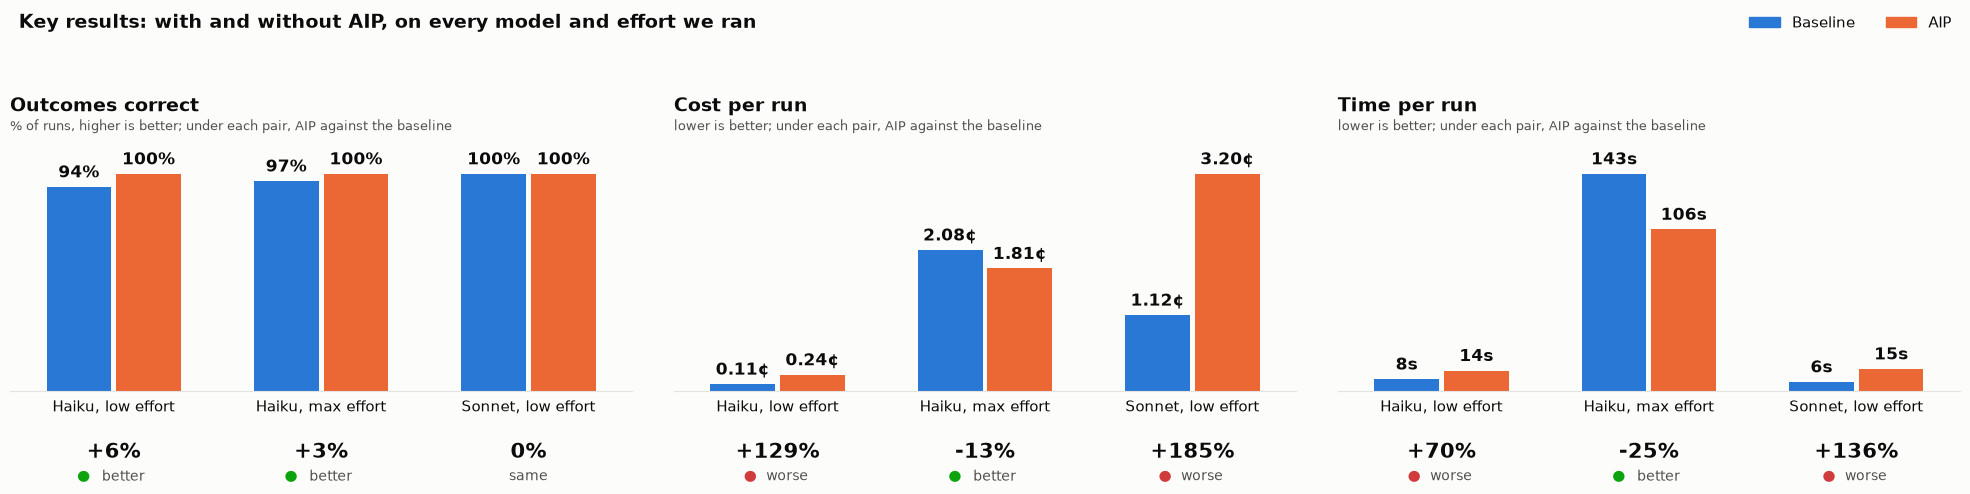

In [2]:
variants_figure(["outcome", "cost", "time"], "Key results: with and without AIP, on every model and effort we ran", "key-results.png", columns=3)

- **Outcomes correct:** the share of runs whose outcome (return, decline, approve or escalate) matched the application's known answer. ¹
- **Cost per run:** in cents, as Claude Code reported it for the run. ²
- **Time per run:** seconds from the start of the run to its answer. ³
- **Auditability:** a fourth headline measure is still to be chosen. Section 6 has the candidates.

<small>¹ Each application's answer is fixed when it is written (`make_applications.py`); the hard-rule part is recomputed from the form. A run counts when its `outcome` field equals that answer. The lists of rules and missing items are scored separately, in section 3.<br>
² Claude Code reports a cost for every run, which is its token counts by kind at list price. Section 4 shows the breakdown. The decision model's calls are not included; at list price they add about 0.005¢ a run to the AIP bars.<br>
³ The `duration_ms` Claude Code reports, which covers the model's calls, the tools and, for AIP, the procedure's scripts and decision-model calls. It leaves out starting the container.</small>

## 3. Outcomes and rules

### What kind of mistake

Every wrong run in this benchmark is one of two kinds. No variant made the third.

- **Approvable application escalated:** the right answer was approve, and the run sent it to a credit officer.
- **Right outcome, one rule too many:** the outcome was right, and the run named a rule or a missing item that did not apply.
- **A problem missed:** a rule or missing item left out, or an approval that should not have been one. This did not happen in any run.

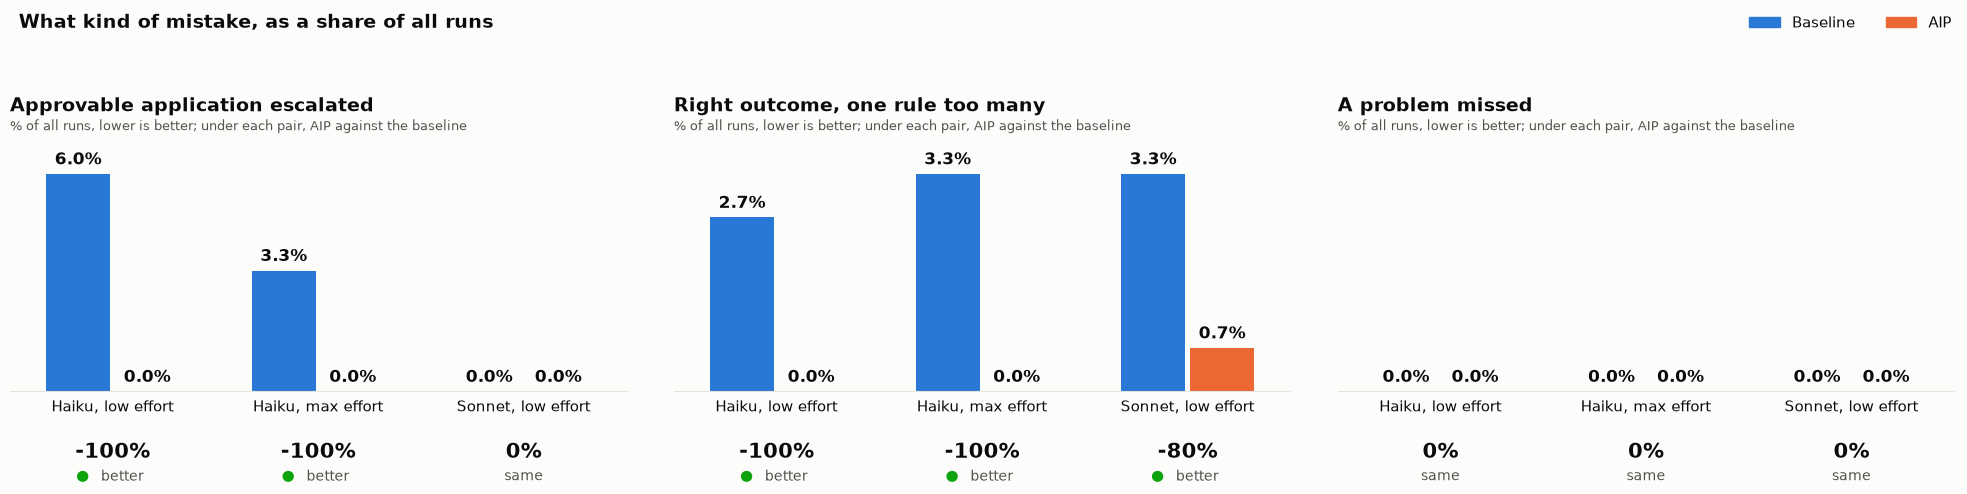

In [3]:
variants_figure(["needless_escalation", "extra_rule", "missed_problem"], "What kind of mistake, as a share of all runs", "failure-types.png", columns=3)

### Where, and why

Every application a variant got wrong at least once, with the answers it gave.

- **The baselines over-read.** Their mistakes are judgment rules flagged on applications where the rule holds: most often J3 (adverse items explained), on applications that mention a late payment or a setback and explain it fully.
- **AIP on Sonnet has one miss, and it is the decision model's.** On one run of APP-2005 the decision model answered that J5 holds at a probability of 0.73, just under the 0.75 bar, so J5 was added beside the expected J3. The other four runs of that application scored J5 from 0.79 to 0.86. The outcome, escalate, was right in all five.
- **AIP on Haiku has none**, at either effort.

In [4]:
def wrong_answers():
    rows = []
    for (group, arm, application), part in runs.groupby(["group", "arm", "application"]):
        if part.decided.all():
            continue
        answers = (part.got + " [" + part.got_failed_rules + "]").value_counts()
        want = EXPECTED[application]
        rows.append({"runs": group, "arm": arm, "application": application, "tier": want["difficulty"],
                     "expected": f"{want['outcome']} [{' '.join(want['failed_rules'])}]",
                     "answers given": ";  ".join(f"{a} x{n}" for a, n in answers.items())})
    return pd.DataFrame(rows).set_index(["runs", "arm", "application"])

display(Markdown("**Every application an arm got wrong at least once, and the answers it gave**"))
display(wrong_answers())

**Every application an arm got wrong at least once, and the answers it gave**

tier       expected  \
runs       arm      application                        
Haiku low  Baseline APP-2001     easy     approve []   
                    APP-2004     easy  escalate [J1]   
                    APP-2005     easy  escalate [J3]   
                    APP-2201     hard     approve []   
                    APP-2209     hard  escalate [J1]   
                    APP-2210     hard     approve []   
Haiku max  Baseline APP-2001     easy     approve []   
                    APP-2005     easy  escalate [J3]   
Sonnet low AIP      APP-2005     easy  escalate [J3]   
           Baseline APP-2008     easy  escalate [J2]   

                                                          answers given  
runs       arm      application                                          
Haiku low  Baseline APP-2001           approve [] x3;  escalate [J3] x2  
                    APP-2004     escalate [J1] x4;  escalate [J1 J2] x1  
                    APP-2005     escalate [J3] x4;  escalate [J3 J5] x1  
                    APP-2201           approve [] x3;  escalate [J3] x2  
                    APP-2209     escalate [J1] x3;  escalate [J1 J2] x2  
                    APP-2210                           escalate [J3] x5  
Haiku max  Baseline APP-2001                           escalate [J3] x2  
                    APP-2005                        escalate [J3 J5] x2  
Sonnet low AIP      APP-2005     escalate [J3] x4;  escalate [J3 J5] x1  
           Baseline APP-2008                        escalate [J1 J2] x5

**A caveat on how hard this is.** The task is one page of application against twelve rules. Sonnet at low effort gets every outcome right with almost no thinking, so this benchmark cannot show AIP improving Sonnet's outcomes. It also has few applications where a problem is easy to overlook, which is why no variant missed one. A harder, longer task is needed to test both.

### What a false positive costs

A wrong escalation is the safe direction, and it is not free: a credit officer reviews an application that needed no review. Outcomes that are 94% correct sound close to done. But the wrong 6% all fall on clean applications, where they are one in four.

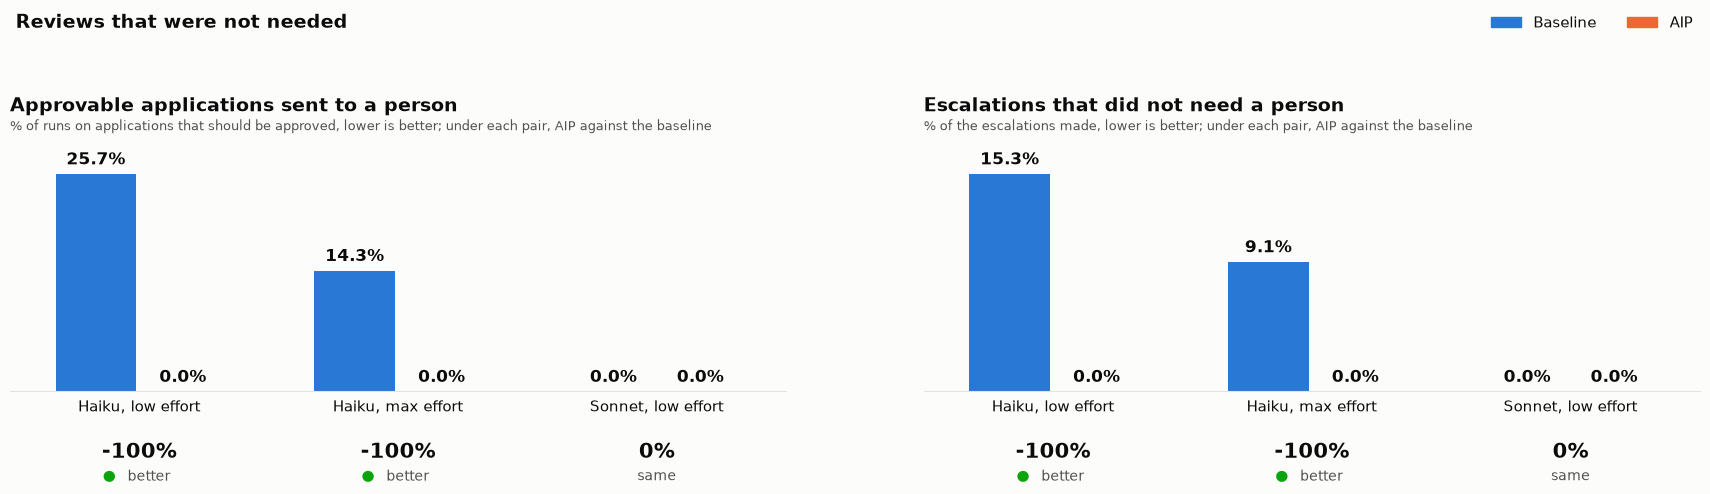

In [5]:
variants_figure(["needless_reviews", "false_escalations"], "Reviews that were not needed", "needless-reviews-all.png", columns=2)

- **Approvable applications sent to a person:** of the runs on the seven applications that should be approved, the share that were escalated.
- **Escalations that did not need a person:** of the runs that escalated, the share where the right outcome was not an escalation. This one depends on how many applications are escalations by design; here that is a third, far more than a real loan book.

**Taking one failure out to scale.** The table below prices only the needless reviews. It does not extrapolate the model's cost, which this benchmark is too small to project.

| Assumption | Value |
|---|---|
| Cost of one needless review | $30: 30 minutes of a credit officer at $60 an hour, fully loaded |
| Share of applications that are clean and should be approved | 40% |
| Rate at which a clean application is wrongly escalated | as measured, with its 95% interval |

The measured rates rest on 35 runs (14 at max effort) over seven applications, so the interval is wide. Read the dollar figures as a scale, not an estimate.

In [6]:
REVIEW_COST, CLEAN_SHARE, SCALES = 30, 0.40, [10_000, 100_000, 1_000_000, 10_000_000]

def interval(wrong, total, z=1.96):
    """The Wilson 95% interval for a share."""
    share = wrong / total
    middle = (share + z * z / (2 * total)) / (1 + z * z / total)
    half = z * ((share * (1 - share) / total + z * z / (4 * total * total)) ** 0.5) / (1 + z * z / total)
    return max(middle - half, 0), min(middle + half, 1)

at_scale, largest = {}, {}
for group in GROUPS:
    for arm in ("Baseline", "AIP"):
        clean = pick(group, arm)
        clean = clean[clean.expected == "approve"]
        wrong, total = int((clean.got == "escalate").sum()), len(clean)
        low, high = interval(wrong, total)
        label = f"{arm}, {group}"
        at_scale[label] = {"Clean applications escalated": f"{wrong} of {total} ({wrong / total:.0%})",
                           **{f"{scale:,} applications a year": f"${scale * CLEAN_SHARE * wrong / total * REVIEW_COST:,.0f}" for scale in SCALES}}
        largest[label] = {"Rate, 95% interval": f"{low:.0%} to {high:.0%}",
                          "Needless reviews a year": f"{SCALES[-1] * CLEAN_SHARE * wrong / total:,.0f}",
                          "Cost a year": f"${SCALES[-1] * CLEAN_SHARE * wrong / total * REVIEW_COST:,.0f}",
                          "Cost a year, 95% interval": f"${SCALES[-1] * CLEAN_SHARE * low * REVIEW_COST:,.0f} to ${SCALES[-1] * CLEAN_SHARE * high * REVIEW_COST:,.0f}"}
display(Markdown("**The cost of needless reviews a year, by how many applications the lender takes**"))
display(pd.DataFrame(at_scale).T)
display(Markdown(f"**At {SCALES[-1]:,} applications a year, with the interval the small sample allows**"))
display(pd.DataFrame(largest).T)

**The cost of needless reviews a year, by how many applications the lender takes**

,Clean applications escalated,"10,000 applications a year","100,000 applications a year","1,000,000 applications a year","10,000,000 applications a year"
"Baseline, Haiku low",9 of 35 (26%),"$30,857","$308,571","$3,085,714","$30,857,143"
"AIP, Haiku low",0 of 35 (0%),$0,$0,$0,$0
"Baseline, Haiku max",2 of 14 (14%),"$17,143","$171,429","$1,714,286","$17,142,857"
"AIP, Haiku max",0 of 14 (0%),$0,$0,$0,$0
"Baseline, Sonnet low",0 of 35 (0%),$0,$0,$0,$0
"AIP, Sonnet low",0 of 35 (0%),$0,$0,$0,$0


**At 10,000,000 applications a year, with the interval the small sample allows**

,"Rate, 95% interval",Needless reviews a year,Cost a year,"Cost a year, 95% interval"
"Baseline, Haiku low",14% to 42%,"1,028,571","$30,857,143","$16,995,442 to $50,483,549"
"AIP, Haiku low",0% to 10%,0,$0,"$0 to $11,868,512"
"Baseline, Haiku max",4% to 40%,"571,429","$17,142,857","$4,811,169 to $47,930,289"
"AIP, Haiku max",0% to 22%,0,$0,"$0 to $25,838,041"
"Baseline, Sonnet low",0% to 10%,0,$0,"$0 to $11,868,512"
"AIP, Sonnet low",0% to 10%,0,$0,"$0 to $11,868,512"


A variant with no needless escalation in 35 runs still has an interval that reaches about 10%: the benchmark cannot tell zero from a few percent.

### Precision and recall of the rules and missing items

Pooling every rule and missing item the runs named:

- **Precision:** of the items named, the share that were right.
- **Recall:** of the right items, the share that were named.

Recall is 100% for every variant, which is the same finding as above from another side: nothing was left out, so every error is an extra item, and the whole difference is precision.

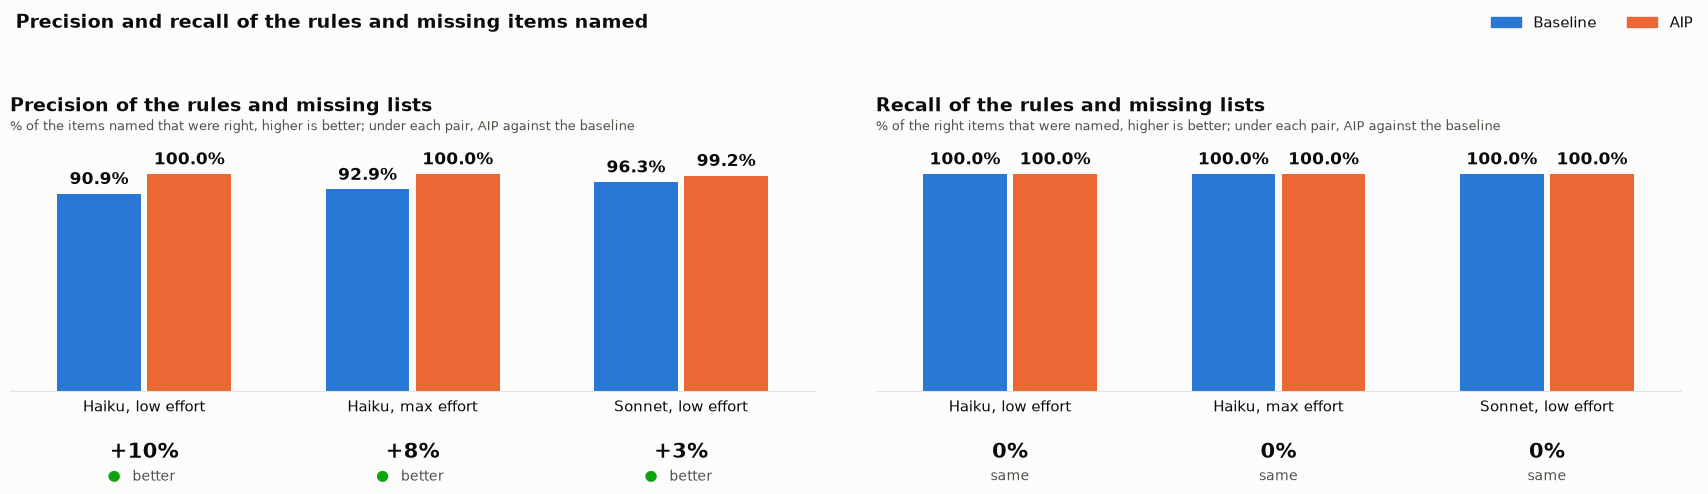

In [7]:
variants_figure(["precision", "recall"], "Precision and recall of the rules and missing items named", "precision-recall.png", columns=2)

## 4. Cost and tokens

**How cost is calculated.** Claude Code reports, for every run, how many tokens of each kind the model used and one cost in dollars. The cost is those token counts at the model's list price. Nothing here is estimated from a rate card: the prices below are recovered from the runs themselves, by fitting each run's reported cost to its token counts.

- **Input, not cached:** new text sent to the model at full price.
- **Cache write:** text sent for the first time and stored, at a small premium.
- **Cache read:** stored text read again on a later request, at about a tenth of the input price.
- **Output, visible** and **thinking:** what the model writes and what it reasons, both at the output price, the dearest.

In [8]:
KINDS = ["tokens_input", "tokens_cache_write", "tokens_cache_read", "tokens_visible", "tokens_thinking"]
PRICES = {model: fit_prices(runs[runs.model == model]) for model in runs.model.unique()}
display(Markdown("**Price per million tokens, recovered from the runs' reported costs**"))
display(pd.DataFrame({model.capitalize(): {TYPES[k]: f"${prices[k] * 1e6:,.2f}" for k in KINDS} for model, (prices, _) in PRICES.items()}))
print("Largest gap between a run's reported cost and its cost at these prices: " + ", ".join(f"{model} ${error:.6f}" for model, (_, error) in PRICES.items()))

tokens_table, cents_table, share_table = {}, {}, {}
for group, arm, _, _ in RUNS:
    part = pick(group, arm)
    prices = PRICES[part.model.iloc[0]][0]
    cents = {k: part[k].mean() * prices[k] * 100 for k in KINDS}
    label = (arm, group)
    tokens_table[label] = {**{TYPES[k]: f"{part[k].mean():,.0f}" for k in KINDS}, "All tokens": f"{part.tokens_total.mean():,.0f}"}
    cents_table[label] = {**{TYPES[k]: f"{cents[k]:.3f}¢" for k in KINDS}, "Cost per run": f"{part.cost_exact.mean() * 100:.3f}¢"}
    share_table[label] = {TYPES[k]: f"{cents[k] / sum(cents.values()):.0%}" for k in KINDS}
display(Markdown("**Tokens per run, by kind**"))
display(pd.DataFrame(tokens_table))
display(Markdown("**What each kind costs per run**"))
display(pd.DataFrame(cents_table))
display(Markdown("**Each kind's share of the cost**"))
display(pd.DataFrame(share_table))

**Price per million tokens, recovered from the runs' reported costs**

,Haiku,Sonnet
"Input, not cached",$0.10,$2.00
Cache write,$0.13,$2.50
Cache read,$0.01,$0.10
"Output, visible",$0.50,$10.00
Thinking,$0.50,$10.00


Largest gap between a run's reported cost and its cost at these prices: haiku $0.000000, sonnet $0.000000


**Tokens per run, by kind**

,Baseline,AIP,Baseline,AIP,Baseline,AIP
,Haiku low,Haiku low,Haiku max,Haiku max,Sonnet low,Sonnet low
"Input, not cached",6,13,7,10,6,14
Cache write,"1,188","6,452","19,624","31,563",852,"5,358"
Cache read,"6,287","23,850","14,363","17,458","6,347","24,061"
"Output, visible",902,"2,041","1,155","1,459",723,"1,599"
Thinking,809,751,"35,186","26,413",120,13
All tokens,"9,192","33,107","70,336","76,903","8,048","31,045"


**What each kind costs per run**

,Baseline,AIP,Baseline,AIP,Baseline,AIP
,Haiku low,Haiku low,Haiku max,Haiku max,Sonnet low,Sonnet low
"Input, not cached",0.000¢,0.000¢,0.000¢,0.000¢,0.001¢,0.003¢
Cache write,0.015¢,0.081¢,0.245¢,0.395¢,0.213¢,1.339¢
Cache read,0.006¢,0.024¢,0.014¢,0.017¢,0.063¢,0.241¢
"Output, visible",0.045¢,0.102¢,0.058¢,0.073¢,0.723¢,1.599¢
Thinking,0.040¢,0.038¢,1.759¢,1.321¢,0.120¢,0.013¢
Cost per run,0.107¢,0.244¢,2.077¢,1.806¢,1.120¢,3.195¢


**Each kind's share of the cost**

,Baseline,AIP,Baseline,AIP,Baseline,AIP
,Haiku low,Haiku low,Haiku max,Haiku max,Sonnet low,Sonnet low
"Input, not cached",0%,0%,0%,0%,0%,0%
Cache write,14%,33%,12%,22%,19%,42%
Cache read,6%,10%,1%,1%,6%,8%
"Output, visible",42%,42%,3%,4%,65%,50%
Thinking,38%,15%,85%,73%,11%,0%


- **Token counts and cost do not move together.** Most tokens in a run are cache reads, the cheapest kind; most of the cost is output and thinking, the dearest.
- **Where a variant spends decides its bill.** At low effort most of the cost is visible output, then thinking or cache writes. At max effort on Haiku, thinking alone is 73% to 85% of the cost.
- **AIP moves cost from thinking to cache writes.** On Haiku at low effort thinking falls from 38% of the cost to 15% and cache writes rise from 14% to 33%.

## 5. AIP's effect on thinking tokens, caching and latency

AIP changes where the tokens go. It takes work away from the model's reasoning and adds calls to the procedure's tools.

- **Thinking goes down** in every setting, because the checks the model would reason through are done by scripts and the decision model.
- **Cached input goes up,** because a run is several requests in place of two, and each one re-reads the conversation so far.
- **Which effect wins depends on how much the model was thinking.**

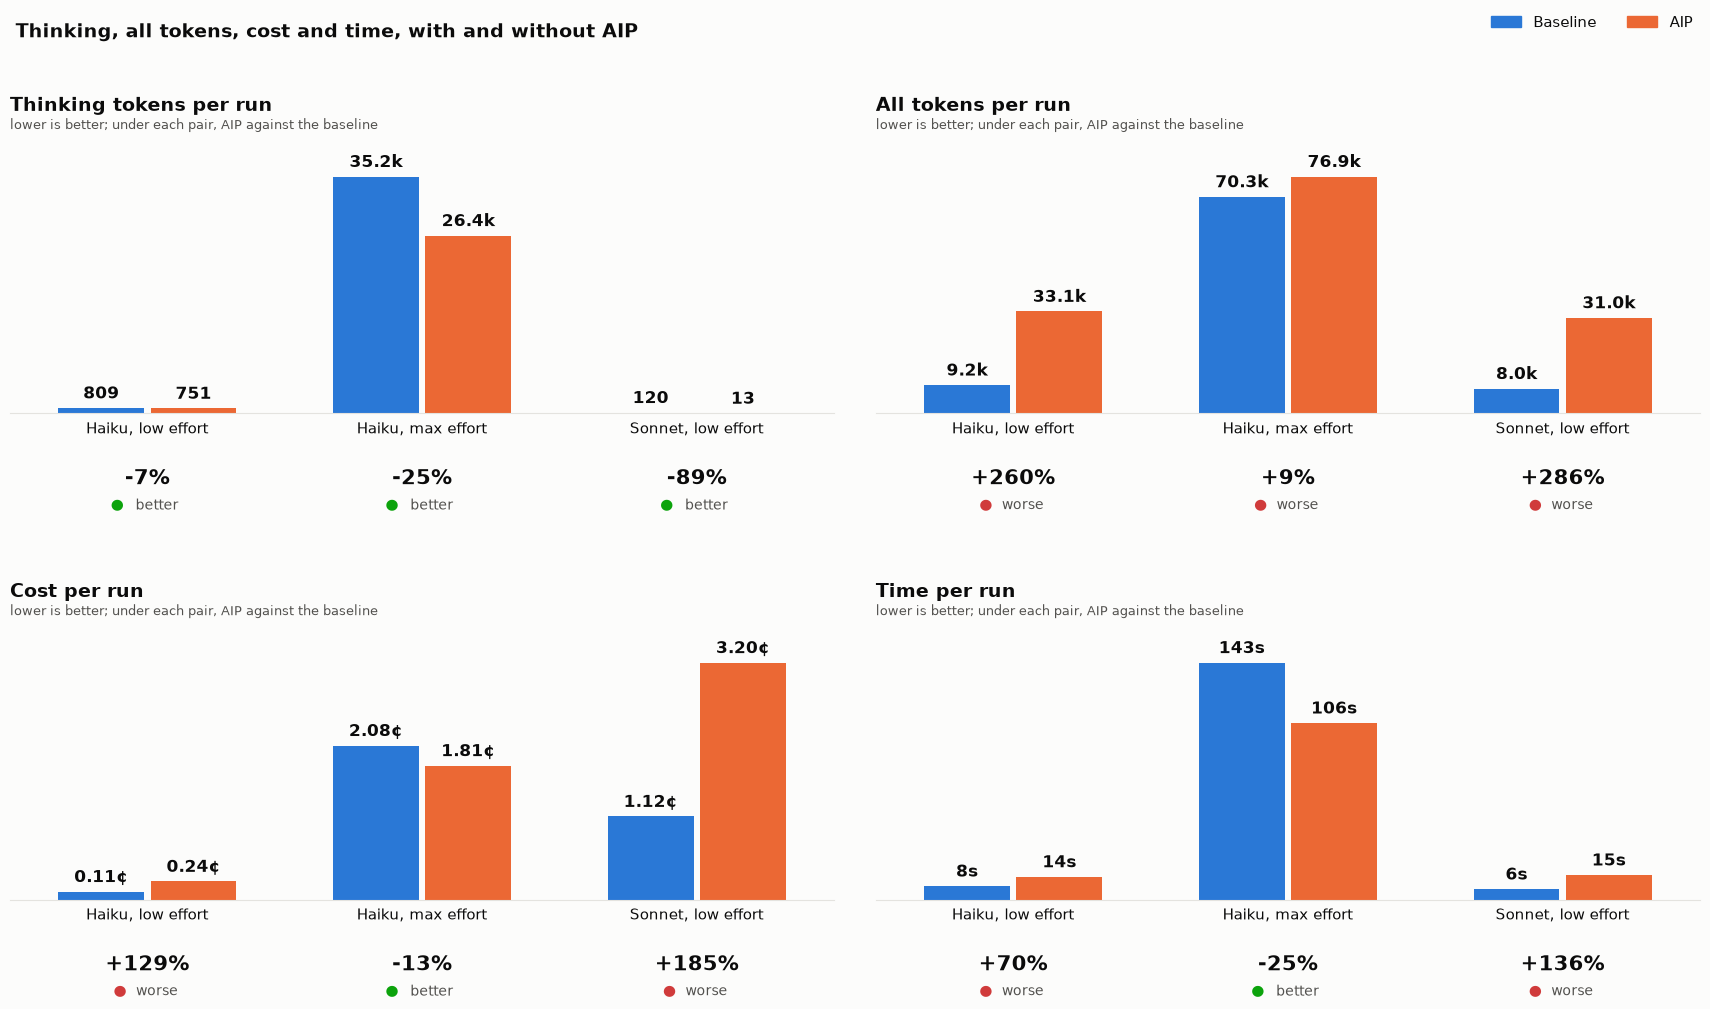

In [9]:
variants_figure(["thinking", "tokens", "cost", "time"], "Thinking, all tokens, cost and time, with and without AIP", "thinking-cost-time.png", columns=2)

- **Haiku at max effort is the one setting where AIP is cheaper and faster.** Thinking falls by 25%, about 8,800 tokens a run at the output price. All tokens still rise by 9%, but the added ones are cached input at a fraction of that price. Cost falls 13% and time falls 25%.
- **At low effort there is little thinking to remove.** Haiku thinks about 800 tokens with or without AIP; Sonnet thinks about 120. AIP's added requests are then pure overhead: on Haiku cost rises 129% and time 70%, and on Sonnet 185% and 136%.
- **So more tokens can mean a lower bill, and fewer can mean a higher one.** Total tokens is the wrong number to watch; the mix is what matters.

**What this suggests.** AIP looks best suited to repeated tasks that make a model reason at length, where the reasoning it removes costs more than the tool calls it adds. That rests on one setting here (Haiku at max effort, 60 runs per variant), so it is a lead to test on a harder task, not a result.

### Where the tokens go, by kind and by tier

Every kind of token on one row for each Haiku effort, over all applications and by tier.

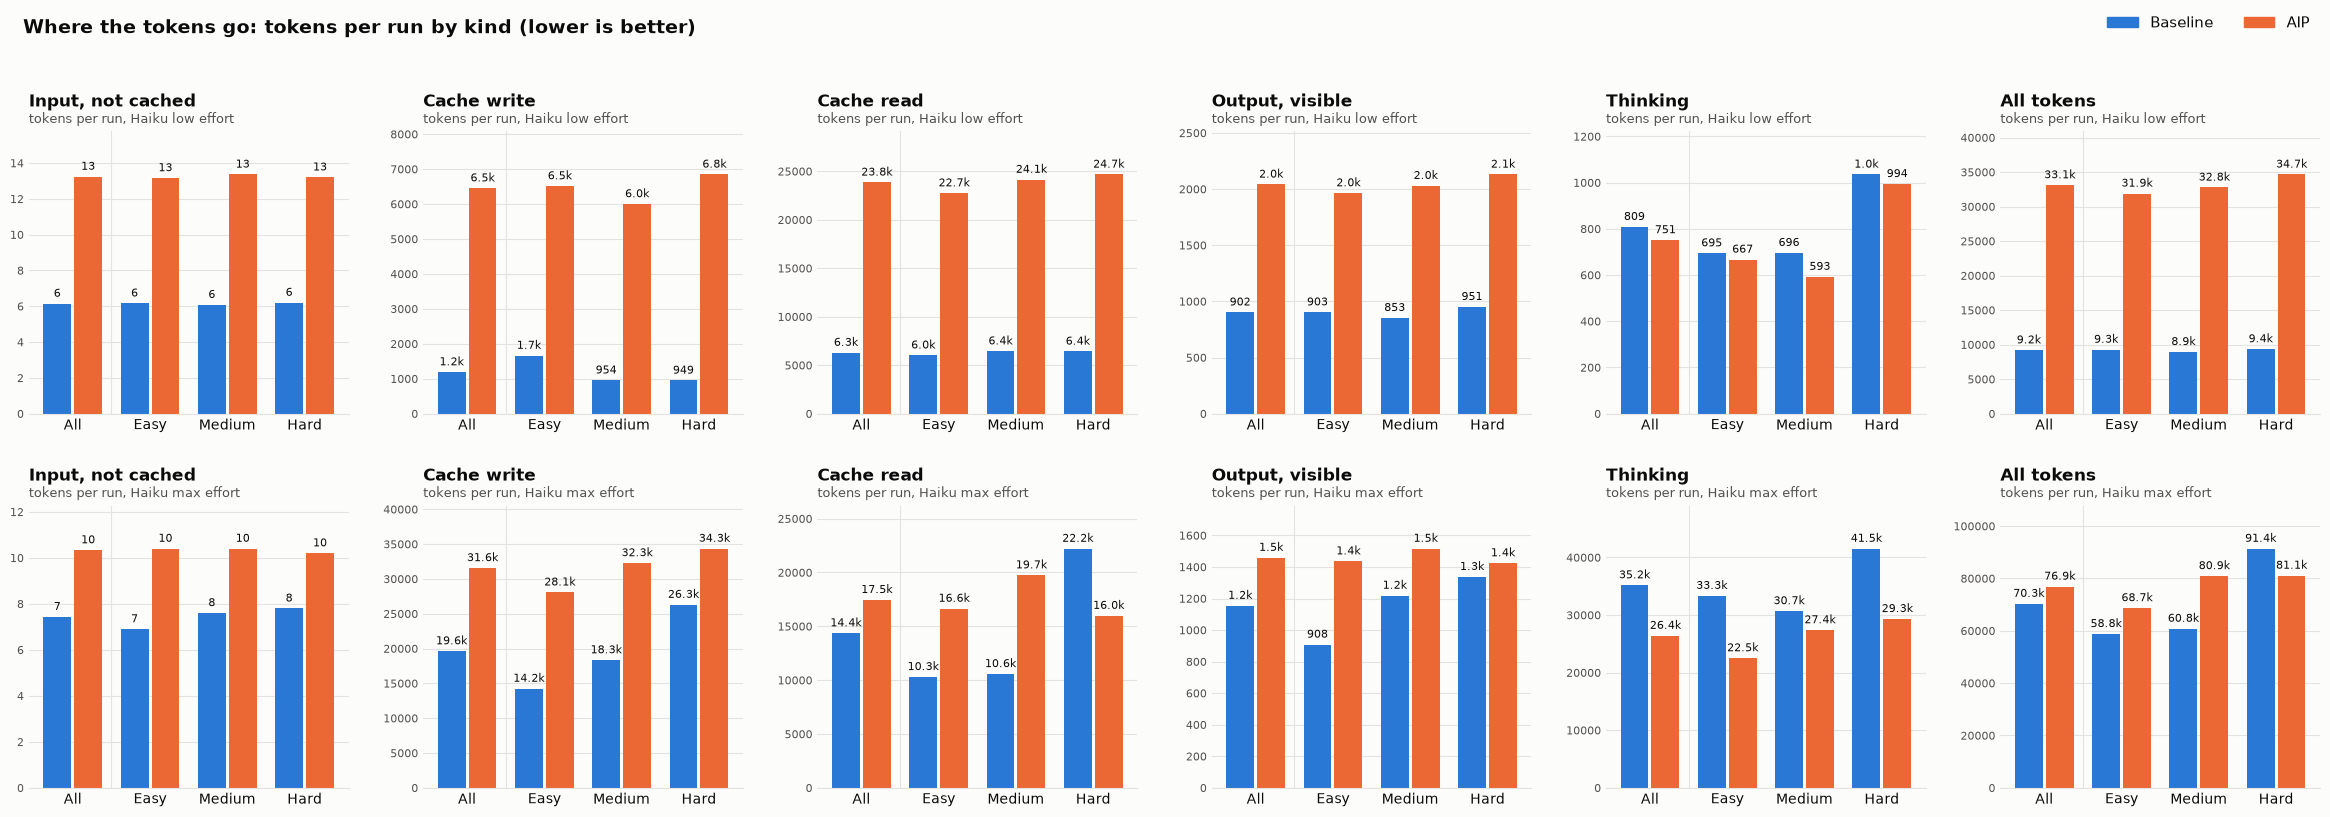

In [10]:
bar_figure(TOKENS, "Where the tokens go: tokens per run by kind (lower is better)", "tokens.png")

### What is happening

**At low effort, AIP adds context and removes nothing.**
- Neither arm thinks much: about 800 tokens each.
- The baseline reads three files and answers, in about 2 requests to the model. AIP calls the procedure's tools and makes 4 to 5, and each request re-reads the conversation so far from the cache.
- So cache writes are about 5 times the baseline's, cache reads about 4 times, visible output about double. All tokens: 3.6 times. Cost: 2.3 times.

**At max effort, AIP thinks less, and thinking is what costs.**
- The baseline thinks about 35,000 tokens a run to reach its decision. With AIP the procedure decides, and the agent thinks about 26,000: a quarter less.
- AIP still adds cached context, about 15,000 tokens a run.
- Net: 9% more tokens, 13% lower cost, 25% less time.

**Why more tokens costs less.** A token's price depends on its kind. AIP removes the dearest kind and adds the cheapest.

| Kind of token | Price per million | Against thinking |
|---|---|---|
| Thinking, and all other output | $0.50 | |
| Cache write | $0.125 | a quarter |
| Cache read | $0.01 | a fiftieth |

The two tables below are that trade, per run. The prices are recovered from the runs' reported costs. The decision model's calls are not Claude tokens and are not counted here.

In [11]:
for group in HAIKU:
    display(Markdown(f"**{group} effort**"))
    display(trade(group))

**Haiku low effort**

,"Tokens, AIP minus baseline",$ per 1M tokens,"Cost, AIP minus baseline"
"Input, not cached",+7,$0.100,+0.000¢
Cache write,"+5,264",$0.125,+0.066¢
Cache read,"+17,563",$0.010,+0.018¢
"Output, visible","+1,138",$0.500,+0.057¢
Thinking,-57,$0.500,-0.003¢
All tokens,"+23,915",,+0.137¢


**Haiku max effort**

,"Tokens, AIP minus baseline",$ per 1M tokens,"Cost, AIP minus baseline"
"Input, not cached",+3,$0.100,+0.000¢
Cache write,"+11,939",$0.125,+0.149¢
Cache read,"+3,095",$0.010,+0.003¢
"Output, visible",+304,$0.500,+0.015¢
Thinking,"-8,774",$0.500,-0.439¢
All tokens,"+6,567",,-0.271¢


## 6. Auditing and analytics

Two audiences ask questions of these decisions afterwards. An auditor asks about one decision or one rule: was it checked, against what, how sure. An analyst or the team running the AI asks about all of them: where is the model unsure, what takes the time, is it stable.

- **Without AIP,** a run leaves a trace (the files read, the model's turns) and the answer it returned, whose reasons are a note in prose.
- **With AIP,** a run leaves a record of every step and its result, and on a server those records are a graph that can be queried.

**The headline measure for this section is still to be chosen.** Candidates, all measured below: the share of runs whose record accounts for every required rule; the share of an auditor's questions the record answers without a model reading it; the share of judgment rules with a recorded probability.

### Does the record account for every rule?

- **Applications answered the same way every run:** every run of an application gave the same outcome, rules and missing items.
- **Required rule checks on the record:** the policy requires all twelve checks for an application that reaches the judgment rules, the seven hard rules for a decline, and none for a return. For a baseline a rule counts if the answer names it or covers it with a phrase such as "H1-H7 all pass". For AIP it counts if the run file holds a result for it.

The baseline was never asked to list every check, and its two messages are capped at 150 words. This measures what each approach leaves behind as run. The AIP run files come from a repeat of the same 150 runs on 23 November, because the first runs did not keep them; that repeat also got every outcome and list right.

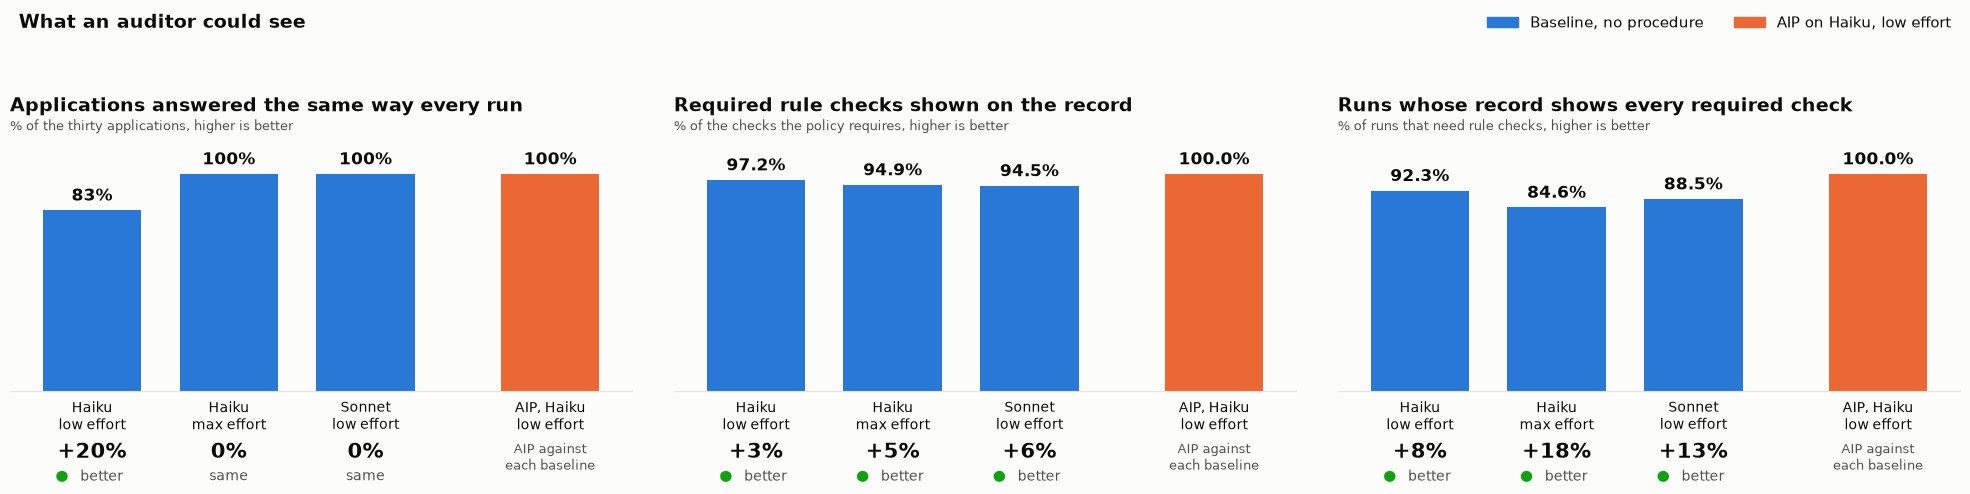

In [12]:
against_figure(["same_every_run", "checks_on_record", "record_complete"], "What an auditor could see", "audit.png")


### The trace beside the record

The same application, once as a trace of the baseline run and once as the record aip keeps. Three applications: an escalation, a decline and an approval.

- **Left, the trace of the baseline on Sonnet:** every tool call and model turn in order, then the answer it returned. This is what a tracing or observability tool has to work from.
- **Right, aip's record of the run on Haiku:** every step in order with its result. Each hard rule has its figure and threshold; each judgment rule has the decision model's answer and probability.

Sonnet's notes are thorough. The difference is less in what is said than in its form: a paragraph the model wrote about its own work, against the outputs of the steps that ran.

In [13]:
import html

def baseline_trace(application, group="Sonnet low", repeat=1):
    """What a trace of the baseline run holds: each tool call and model turn in order, then the answer."""
    folder, cell = next((f, c) for g, a, f, c in RUNS if g == group and a == "Baseline")
    base = str(RESULTS / folder / "runs" / cell / f"{application}.r{repeat}")
    record = json.loads(pathlib.Path(base + ".json").read_text())
    lines, calls = [], set()
    for line in pathlib.Path(base + ".transcript.jsonl").read_text().splitlines():
        try:
            event = json.loads(line)
        except ValueError:
            continue
        if not isinstance(event, dict) or event.get("type") != "assistant":
            continue
        calls.add(event["message"].get("id"))
        for block in event["message"]["content"]:
            if block["type"] == "thinking":
                kept = (block.get("thinking") or "").strip()
                lines.append(("model", "thinking", kept[:200] if kept else "(not kept)"))
            elif block["type"] == "text" and block["text"].strip():
                lines.append(("model", "text", block["text"].strip()[:200]))
            elif block["type"] == "tool_use" and block["name"] == "StructuredOutput":
                answer = block["input"]
                lines.append(("answer", "outcome", answer.get("outcome", "")))
                lines.append(("answer", "failed_rules", json.dumps(answer.get("failed_rules", []))))
                lines.append(("answer", "missing", json.dumps(answer.get("missing", []))))
                lines.append(("answer", "officer_message", answer.get("officer_message", "")))
            elif block["type"] == "tool_use":
                lines.append(("tool", block["name"], str(block["input"].get("file_path") or block["input"].get("command") or block["input"])[:160]))
    claude = record["claude"]
    foot = f"{len(calls)} model calls, {sum(1 for kind, *_ in lines if kind == 'tool')} tool calls, {claude['duration_ms'] / 1000:.0f}s, ${claude['total_cost_usd']:.4f}"
    return f"Baseline, {group} effort", lines, foot

def aip_record(application, key=("Haiku low", "AIP"), repeat=1):
    """What aip recorded for its run: each step in order with its typed result."""
    run = json.loads((RUN_FILES[key] / f"{application}.r{repeat}.aip-runs.json").read_text())[-1]
    lines, rules = [], []
    for entry in run["run"]["history"]:
        result, step, kind = entry.get("result") or {}, entry["step"], entry["kind"]
        if kind in ("Start", "End", "For"):
            continue
        if "hard_rule_results" in result or "missing_items" in result:
            lines.append(("step", f"{step} · script", f"form is {result['form_status']['value']}"))
            for item in result.get("missing_items", []):
                lines.append(("check", "missing", f"{item['name']} ({item['kind']})"))
            for check in result.get("hard_rule_results", []):
                lines.append(("check", check["rule"], f"{check['figure']} · required: {check['threshold']} · {'pass' if check['passed'] else 'FAIL'}"))
        elif "judgment_rules" in result:
            rules = result["judgment_rules"]
            lines.append(("step", f"{step} · script", f"{len(rules)} judgment rules read from the policy"))
        elif kind == "Decide":
            rule, holds = rules[entry["pass"]], result["holds"]
            lines.append(("check", rule["id"], f"{rule['name']} · decision model: {'holds' if holds['value'] else 'does not hold'} · probability it holds {holds['noul']:.2f}"))
        elif kind == "Aggregate":
            lines.append(("step", f"{step} · aggregate", f"every rule holds above the bar: {'yes' if result['all_hold']['value'] else 'no'}"))
        elif kind == "Route":
            lines.append(("step", f"{step} · route", ""))
        elif kind == "Task_Agent":
            lines.append(("step", f"{step} · agent", "wrote the two messages"))
        else:
            lines.append(("step", f"{step} · script", f"outcome {result.get('outcome', '')}, failed_rules {json.dumps(result.get('failed_rules', []))}"))
    seconds = sum(entry.get("seconds") or 0 for entry in run["run"]["history"])
    foot = f"procedure {run['name']}, bundle {run['bundle_id'][:12]}, run {run['run_id']}, {len(lines)} recorded lines"
    return "AIP, Haiku low effort", lines, foot

def column(title, lines, foot, colour):
    rows = "".join(
        f'<tr><td style="padding:2px 10px 2px {0 if kind in ("tool", "model", "step") else 18}px;white-space:nowrap;vertical-align:top;'
        f'color:{INK if kind in ("tool", "model", "step") else MUTED};font-weight:{600 if kind in ("tool", "model", "step") else 400}">{html.escape(name)}</td>'
        f'<td style="padding:2px 0;vertical-align:top;color:{INK};text-align:left">{html.escape(text)}</td></tr>' for kind, name, text in lines)
    return (f'<td style="vertical-align:top;width:50%;padding:0 14px 0 0;text-align:left"><div style="border-top:4px solid {colour};background:{SURFACE};padding:10px 12px">'
            f'<div style="font-weight:700;color:{INK};margin-bottom:6px">{html.escape(title)}</div>'
            f'<table style="font-family:ui-monospace,Menlo,monospace;font-size:12px;border-collapse:collapse">{rows}</table>'
            f'<div style="color:{MUTED};font-size:12px;margin-top:8px">{html.escape(foot)}</div></div></td>')

def side_by_side(application):
    want = EXPECTED[application]
    heading = f"{application}: the right answer is {want['outcome']}" + (f" on {', '.join(want['failed_rules'])}" if want["failed_rules"] else "")
    display(HTML(f'<h4 style="margin:18px 0 6px">{html.escape(heading)}</h4><table style="width:100%;border-collapse:collapse"><tr>'
                 + column(*baseline_trace(application), ARM_COLOR["Baseline"]) + column(*aip_record(application), ARM_COLOR["AIP"]) + "</tr></table>"))

for application in ("APP-2004", "APP-2002", "APP-2001"):
    side_by_side(application)


Read,/work/sop.md
Read,/work/policy.md
Read,/work/application.md
thinking,(not kept)
outcome,escalate
failed_rules,"[""J1""]"
missing,[]
officer_message,"Escalate. Complete; H1–H7 all pass (amount $60,000; term 36; 11 years in business; score 684; no bankruptcy or liens; coverage 11,200/(1,800+1,922)=3.01 vs 1.25; size 11.1% of revenue vs 25%). J1 does NOT hold (very confident, ~0.97): section 5 says ""$20,000 will pay off two credit cards in my own name that I ran up during my divorce"" and ""The last $15,000 is a draw to myself"", which are personal debt and an owner draw. Only the $25,000 mower and trailer is a clear business use. J2 holds (25+20+15=60,000; ~0.95). J3 holds (no adverse items, 0 late payments; ~0.95). J4 holds (repay from 42 renewing maintenance contracts; ~0.9). J5 holds (landscaping since March 2018, consistent with form; ~0.95). Question for the officer: should the loan be considered at all when $35,000 of the $60,000 goes to personal debt and an owner draw, for example at a reduced amount covering only the equipment?"
check_form · script,form is passed
H1,"amount requested $60,000 · required: from $10,000 to $250,000 · pass"
H2,term 36 months · required: from 12 to 60 months · pass


Read,/work/sop.md
Read,/work/policy.md
Read,/work/application.md
thinking,(not kept)
outcome,decline
failed_rules,"[""H6""]"
missing,[]
officer_message,"Decline. H6 Coverage failed: 5,200 / (2,300 + 2,310) = 1.128, against a threshold of 1.25 or higher. All other hard rules pass: H1 $110,000 is within $10k-$250k. H2 60 months is within 12-60. H3 has operated since 2017-09, over 24 months. H4 credit score 698 is above 660. H5 no bankruptcy and no liens. H7 110,000 / 480,000 = 22.9%, within 25%. The application is complete. Judgment rules were not assessed."
check_form · script,form is failed
H1,"amount requested $110,000 · required: from $10,000 to $250,000 · pass"
H2,term 60 months · required: from 12 to 60 months · pass


Read,/work/sop.md
Read,/work/policy.md
Read,/work/application.md
thinking,(not kept)
outcome,approve
failed_rules,[]
missing,[]
officer_message,"Approve. Complete; all hard rules pass. H1 $85,000 (10k–250k). H2 48 months (12–60). H3 operating since 2019-04, over 24 months. H4 score 712 (≥660). H5 no bankruptcy, no liens. H6 coverage 9,400/(1,150+2,135)=2.86 (≥1.25). H7 85,000/612,000=13.9% (≤25%). Judgment rules all hold with high confidence (>0.75): J1 oven, installation and proofing cabinet are business uses; J2 58,000+14,500+12,500=85,000 exactly; J3 no late payments and no adverse items mentioned; J4 repayment from current earnings, wholesale growth explicitly not relied on; J5 story matches the form. Approved: $85,000, 48 months, $2,135 per month."
check_form · script,form is passed
H1,"amount requested $85,000 · required: from $10,000 to $250,000 · pass"
H2,term 48 months · required: from 12 to 60 months · pass


### What each one can answer

| An auditor asks | From the trace | From aip's record |
|---|---|---|
| What was decided, and what reasons were given? | **Yes.** The answer holds the outcome, the rules and a note of up to 150 words. | **Yes.** |
| Was every hard rule checked, and against what figure? | **Usually, in prose.** The note accounts for every required rule in 88% of Sonnet's runs, often as "H1-H7 all pass" with the figures in a list. | **Yes.** Seven results, each with the figure and the threshold. |
| How sure was the judgment on each judgment rule? | **No.** At most a phrase in the note. | **Yes.** A probability for each rule, and the bar it was held to. |
| Which version of the rules made this decision? | **Partly.** The trace holds the text of the files the agent read, with no version to compare by. | **Yes.** The bundle id names the exact procedure and policy. |
| Which other decisions turned on the same rule or a figure near the line? | **By reading.** A text search through the notes. | **By query.** The rule, figure and probability are fields. |

The left column is this baseline as it was run. An agent that works in visible steps leaves more in its trace: at max effort Haiku ran a calculation in a shell in about half its runs. That is still text to read, not a rule and its result.


### The same questions, measured

The table above says what each record could answer. This one counts how often it does, over every run whose application needs rule checks.

- **For the baselines,** a model (Claude Sonnet, `bench/extract.py`) read each answer and copied out the figures it states, with nothing worked out. That is the reading an auditor would have to do. Each figure is then checked against the form.
- **For AIP,** the figures are read from fields of the run file.
- **A figure counts** when the record states it and it matches the form: exact for the amount, term and score, within 0.01 for coverage, within half a point for size, and within a year for time in business.


In [14]:
import make_applications

def form_truth():
    """Each application's true figures, worked out from its form, for the applications that need rule checks."""
    truth = {}
    for a in make_applications.APPS:
        if a["expect"] == "return" or a["id"] not in EXPECTED:
            continue
        payment = make_applications.quoted_payment(a["amount"], a["term"])
        months = (int(a["received"][:4]) - int(a["since"][:4])) * 12 + int(a["received"][5:7]) - int(a["since"][5:7])
        truth[a["id"]] = dict(amount=a["amount"], term=a["term"], months=months, since=a["since"], score=a["score"],
                              coverage=a["income"] / (a["debt"] + payment), percent=a["amount"] / a["revenue"] * 100)
    return truth

def baseline_figures(group):
    """The figures a model read out of each baseline answer (bench/extract.py): what the answer states, or None."""
    folder, cell = next((f, c) for g, a, f, c in RUNS if g == group and a == "Baseline")
    for path in sorted((RESULTS / folder / "runs" / cell).glob("*.extract.json")):
        x = json.loads(path.read_text())
        yield path.name.split(".")[0], dict(amount=x["amount_requested"], term=x["term_months"], months=x["months_in_business"], since=x["operating_since"],
                                            score=x["credit_score"], coverage=x["coverage_ratio"], percent=x["amount_percent_of_revenue"],
                                            sure=[x[f"j{n}_probability"] for n in range(1, 6)], liens=x["bankruptcy_or_liens"])

def aip_figures(key=("Haiku low", "AIP")):
    """The same figures from aip's run files, where each is a field of a step's result."""
    for path in sorted(RUN_FILES[key].glob("*.aip-runs.json")):
        figure, sure = {}, []
        for entry in json.loads(path.read_text())[-1]["run"]["history"]:
            result = entry.get("result") or {}
            figure.update({check["rule"]: check["figure"] for check in result.get("hard_rule_results", [])})
            if entry["kind"] == "Decide":
                sure.append(result["holds"]["noul"])
        def number(rule, pattern):
            found = re.search(pattern, figure.get(rule, ""))
            return float(found.group(1).replace(",", "")) if found else None
        since = re.search(r"since (\d{4}-\d{2})", figure.get("H3", ""))
        yield path.name.split(".")[0], dict(amount=number("H1", r"\$([\d,]+)"), term=number("H2", r"term (\d+)"), months=number("H3", r"(\d+) months"),
                                            since=since.group(1) if since else None, score=number("H4", r"score (\d+)"),
                                            coverage=number("H6", r"coverage ([\d.]+)"), percent=number("H7", r"is ([\d.]+)%"), sure=sure, liens=figure.get("H5"))

TRUTH = form_truth()
WITHIN = {"amount": 0, "term": 0, "score": 0, "coverage": 0.011, "percent": 0.6}
FIGURE_OF = {"H1": "amount", "H2": "term", "H3": "time", "H4": "score", "H6": "coverage", "H7": "percent"}

def audit(rows):
    """How many of an auditor's questions each run's record answers, and how many of its stated figures are wrong."""
    count = collections.Counter()
    for application, said in rows:
        if application not in TRUTH:
            continue
        true, want = TRUTH[application], EXPECTED[application]
        right = {k: said[k] is not None and abs(said[k] - true[k]) <= w for k, w in WITHIN.items()}
        right["time"] = said["since"] == true["since"] or (said["months"] is not None and abs(said["months"] - true["months"]) <= 12)
        count["runs"] += 1
        count["coverage"] += right["coverage"]
        count["every figure"] += all(right.values())
        count["stated"] += sum(said[k] is not None for k in (*WITHIN, "months"))
        count["wrong"] += sum(said[k] is not None and abs(said[k] - true[k]) > w for k, w in {**WITHIN, "months": 12}.items())
        if want["outcome"] == "decline":
            count["declines"] += 1
            count["decline figure"] += all(right[FIGURE_OF[rule]] if rule in FIGURE_OF else bool(said["liens"]) for rule in want["failed_rules"])
        else:
            count["judged"] += 1
            count["five numbers"] += sum(p is not None for p in said["sure"]) == 5
        if true["coverage"] < 1.5 and want["outcome"] != "decline":
            count["thin"] += 1
            count["thin found"] += right["coverage"]
    return count

AUDITS = {**{f"Baseline, {group}": audit(baseline_figures(group)) for group in GROUPS}, "AIP, Haiku low": audit(aip_figures())}
of = lambda count, part, whole: f"{count[part]} of {count[whole]} ({count[part] / count[whole]:.0%})"
QUESTIONS = {
    "Why was this one declined: the failed rule's own figure?": lambda c: of(c, "decline figure", "declines"),
    "What was the coverage ratio on this decision?": lambda c: of(c, "coverage", "runs"),
    "Every hard-rule figure for this decision: amount, term, time in business, score, coverage, size?": lambda c: of(c, "every figure", "runs"),
    "How sure was the judgment on each of the five judgment rules, as a number?": lambda c: of(c, "five numbers", "judged"),
    "Which approved or escalated decisions had coverage under 1.5?": lambda c: of(c, "thin found", "thin"),
    "Figures the record states that do not match the form": lambda c: f"{c['wrong']} of {c['stated']} ({c['wrong'] / c['stated']:.1%})",
}
display(pd.DataFrame({name: {question: answer(count) for question, answer in QUESTIONS.items()} for name, count in AUDITS.items()}))


,"Baseline, Haiku low","Baseline, Haiku max","Baseline, Sonnet low","AIP, Haiku low"
Why was this one declined: the failed rule's own figure?,45 of 45 (100%),18 of 18 (100%),45 of 45 (100%),45 of 45 (100%)
What was the coverage ratio on this decision?,128 of 130 (98%),34 of 52 (65%),130 of 130 (100%),130 of 130 (100%)
"Every hard-rule figure for this decision: amount, term, time in business, score, coverage, size?",128 of 130 (98%),30 of 52 (58%),112 of 130 (86%),130 of 130 (100%)
"How sure was the judgment on each of the five judgment rules, as a number?",2 of 85 (2%),29 of 34 (85%),14 of 85 (16%),85 of 85 (100%)
Which approved or escalated decisions had coverage under 1.5?,10 of 10 (100%),4 of 4 (100%),10 of 10 (100%),10 of 10 (100%)
Figures the record states that do not match the form,3 of 759 (0.4%),4 of 219 (1.8%),4 of 652 (0.6%),0 of 780 (0.0%)


- **Declines are covered either way.** Every variant gave the failed rule's own figure on every decline.
- **The gap is in how sure the judgment was.** AIP records a probability for every judgment rule. A baseline's note gives a number for all five in 2% to 85% of runs, depending on the model and effort, and that number is the model's estimate of itself.
- **A small share of stated figures are wrong.** For example, one Sonnet note says "11 years in business" for a business the form shows as 8 years 8 months old. AIP's figures come from a script.
- **Getting these numbers out of the baselines took a model call per run.** That reading step is the cost of analytics without a record.

### Analytics: a question as a query

With AIP the runs are a graph on the server: a `Run` has `Entry` nodes for its steps, and a decision's `Entry` gave an `Answer` with a value and a confidence. A question about every run is one Cypher query. Without it, the same question starts by reading each run's note.

To build this, the 150 saved run files were posted to an aip server (`bench/load_runs.py`) and the queries run against its graph (`bench/queries/`). The answers shown are what the queries returned.

In [15]:
QUERIES = json.loads((DEMO / "bench" / "queries" / "queries.json").read_text())
ANSWERS = {a["question"]: a["rows"] for a in json.loads((DEMO / "bench" / "queries" / "results.json").read_text())}
for number, query in enumerate(QUERIES, 1):
    rows = pd.DataFrame(ANSWERS[query["question"]])
    display(HTML(
        f'<h4 style="margin:22px 0 6px">{number}. {html.escape(query["question"])}</h4>'
        f'<table style="width:100%;border-collapse:collapse"><tr>'
        f'<td style="width:34%;vertical-align:top;text-align:left;padding:0 14px 0 0"><div style="border-top:4px solid {ARM_COLOR["Baseline"]};background:{SURFACE};padding:10px 12px">'
        f'<div style="font-weight:700;color:{INK};margin-bottom:4px">Without AIP</div><div style="color:{INK}">{html.escape(query["baseline"])}</div></div></td>'
        f'<td style="vertical-align:top;text-align:left;padding:0"><div style="border-top:4px solid {ARM_COLOR["AIP"]};background:{SURFACE};padding:10px 12px">'
        f'<div style="font-weight:700;color:{INK};margin-bottom:4px">With AIP: one query</div>'
        f'<pre style="margin:0;font-size:12px;white-space:pre-wrap;color:{INK};background:transparent">{html.escape(query["cypher"])}</pre></div></td></tr></table>'))
    display(rows.head(12))
    if len(rows) > 12:
        print(f"{len(rows)} rows in all; the first 12 are shown")

Without AIPRead the outcome field of each saved answer and count. This one is as easy without AIP.,"With AIP: one queryMATCH (r:Run {name: 'assess_term_loan'})-[:HAS_ENTRY]->(e:Entry) WHERE r.session IS NOT NULL AND e.step IN ['return_application', 'decline', 'approve', 'escalate'] RETURN e.step AS ending, count(*) AS runs ORDER BY runs DESC"


,ending,runs
0,escalate,50
1,decline,45
2,approve,35
3,return_application,20


"Without AIPNot recorded. A model has to read each officer note for a stated confidence (bench/extract.py, one call per run); Sonnet's notes give a number for all five rules in 16% of runs, and it is the model's own estimate.","With AIP: one queryMATCH (r:Run {name: 'assess_term_loan'})-[:HAS_ENTRY]->(e:Entry {step: 'judge_rule'})-[:GAVE]->(a:Answer) WHERE r.session IS NOT NULL RETURN 'J' + toString(e.pass + 1) AS rule, a.value AS holds, count(*) AS decisions, round(min(a.confidence), 2) AS least_sure, round(avg(a.confidence), 2) AS average ORDER BY rule, holds"


,rule,holds,decisions,least_sure,average
0,J1,False,15,0.96,0.97
1,J1,True,70,0.78,0.94
2,J2,False,10,0.74,0.79
3,J2,True,75,0.84,0.95
4,J3,False,10,0.86,0.91
5,J3,True,75,0.64,0.93
6,J4,False,5,0.96,0.96
7,J4,True,80,0.66,0.92
8,J5,False,10,0.78,0.88
9,J5,True,75,0.54,0.80


Without AIPNot answerable from most records: needs a confidence for every rule on every approval.,"With AIP: one queryMATCH (r:Run {name: 'assess_term_loan'})-[:HAS_ENTRY]->(:Entry {step: 'approve'}) MATCH (r)-[:HAS_ENTRY]->(e:Entry {step: 'judge_rule'})-[:GAVE]->(a:Answer) WHERE a.confidence < 0.85 RETURN r.session AS application, 'J' + toString(e.pass + 1) AS rule, count(DISTINCT r) AS runs, round(min(a.confidence), 2) AS least_sure ORDER BY least_sure"


,application,rule,runs,least_sure
0,APP-2210,J5,5,0.68
1,APP-2201,J3,5,0.72
2,APP-2006,J5,5,0.76
3,APP-2110,J5,5,0.76
4,APP-2110,J3,5,0.76
5,APP-2110,J1,5,0.78
6,APP-2201,J1,3,0.78
7,APP-2101,J5,4,0.80
8,APP-2104,J5,1,0.82
9,APP-2201,J5,5,0.82


... (3 outputs left out)

Without AIPThe trace has one duration for the whole run and one per model call; there are no steps to attribute it to.,"With AIP: one queryMATCH (r:Run {name: 'assess_term_loan'})-[:HAS_ENTRY]->(e:Entry) WHERE r.session IS NOT NULL AND e.kind IN ['Execute', 'Decide', 'Task_Agent'] RETURN e.step AS step, e.kind AS kind, count(*) AS times_run, round(avg(coalesce(e.waited_seconds, e.seconds)), 3) AS average_seconds ORDER BY average_seconds DESC"


,step,kind,times_run,average_seconds
0,write_messages,Task_Agent,148,5.814
1,judge_rule,Decide,425,0.157
2,check_form,Execute,150,0.036
3,escalate,Execute,50,0.022
4,approve,Execute,35,0.020
5,decline,Execute,45,0.019
6,return_application,Execute,20,0.019
7,list_judgment_rules,Execute,85,0.014


Without AIPThe trace holds the text of the files the agent read. Hash that text in each transcript and compare.,"With AIP: one queryMATCH (r:Run {name: 'assess_term_loan'}) WHERE r.session IS NOT NULL RETURN r.name AS procedure, r.revision AS revision, left(r.bundle_id, 12) AS bundle, count(*) AS runs"


,procedure,revision,bundle,runs
0,assess_term_loan,1,aac0063a7732,150


What the queries turned up, which no chart above shows:

- **J5, "the story matches the form", is the rule the decision model is least sure of.** Its average confidence when the rule holds is 0.80, against 0.92 to 0.95 for the others. It is also the rule behind the one AIP miss on Sonnet. That points at the rule's wording, or at its 0.75 bar, as the next thing to tune.
- **The answers never flip between runs, but the confidence drifts** by up to 0.2 on the same application and rule.
- **The agent's one step, writing the messages, is nearly all of a run's time:** about 6 seconds, against a sixth of a second for a decision and hundredths for a script.

**One limit found on the way.** The decisions are fields in the graph, but the hard rules' figures are not: the form check returns all seven as one list, which the server keeps as text inside the step's entry. A query for "every decision with coverage under 1.5" has to parse that text. Having the form check return each hard rule as its own labelled answer would make those fields too; that is a change to the procedure, not to aip.

---

## Appendix

Earlier views and the numbers behind the figures.

### A1. Haiku with and without AIP, at low and at max effort

For each measure, the baseline's value, AIP's value, and the change from one to the other. One row for each effort. Each chart has its own scale, so compare the two bars within a chart and read the numbers to compare between charts.

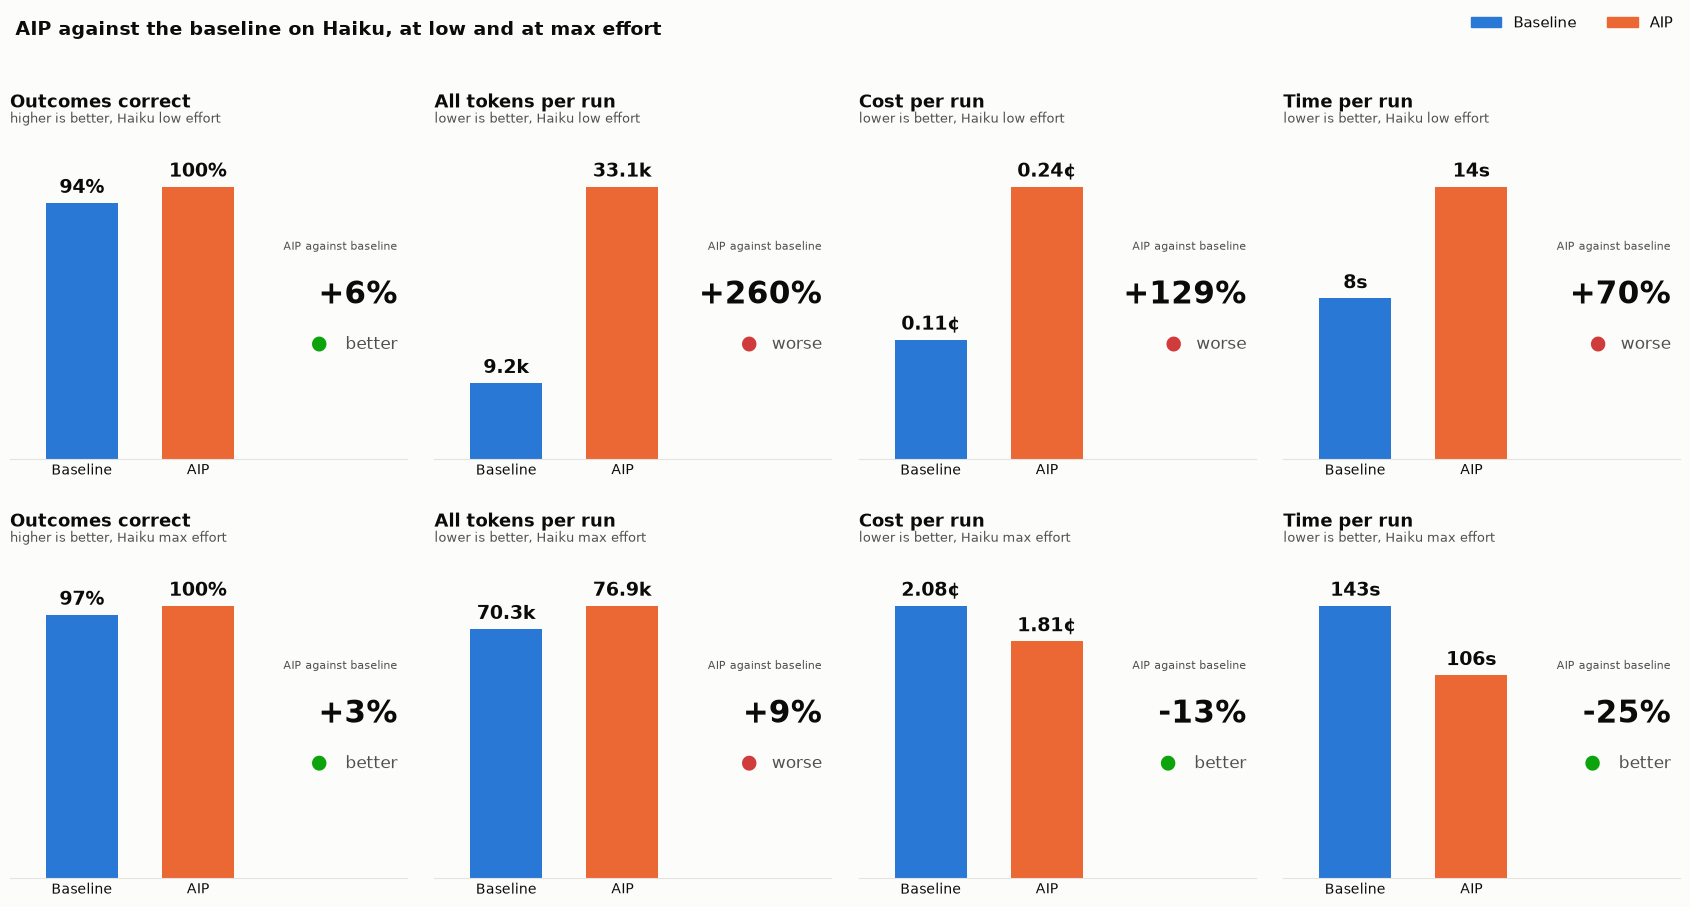

In [16]:
summary_figure([(f"{group} effort", pick(group, "Baseline"), pick(group, "AIP"), "Baseline", "AIP") for group in HAIKU],
               "AIP against the baseline on Haiku, at low and at max effort", "summary.png")

### A2. Share of runs that got each output wrong, by tier

The share of runs that got each output wrong, over all thirty applications and then by tier. The two message charts use a strict scripted rubric, so read them as a rough guide.

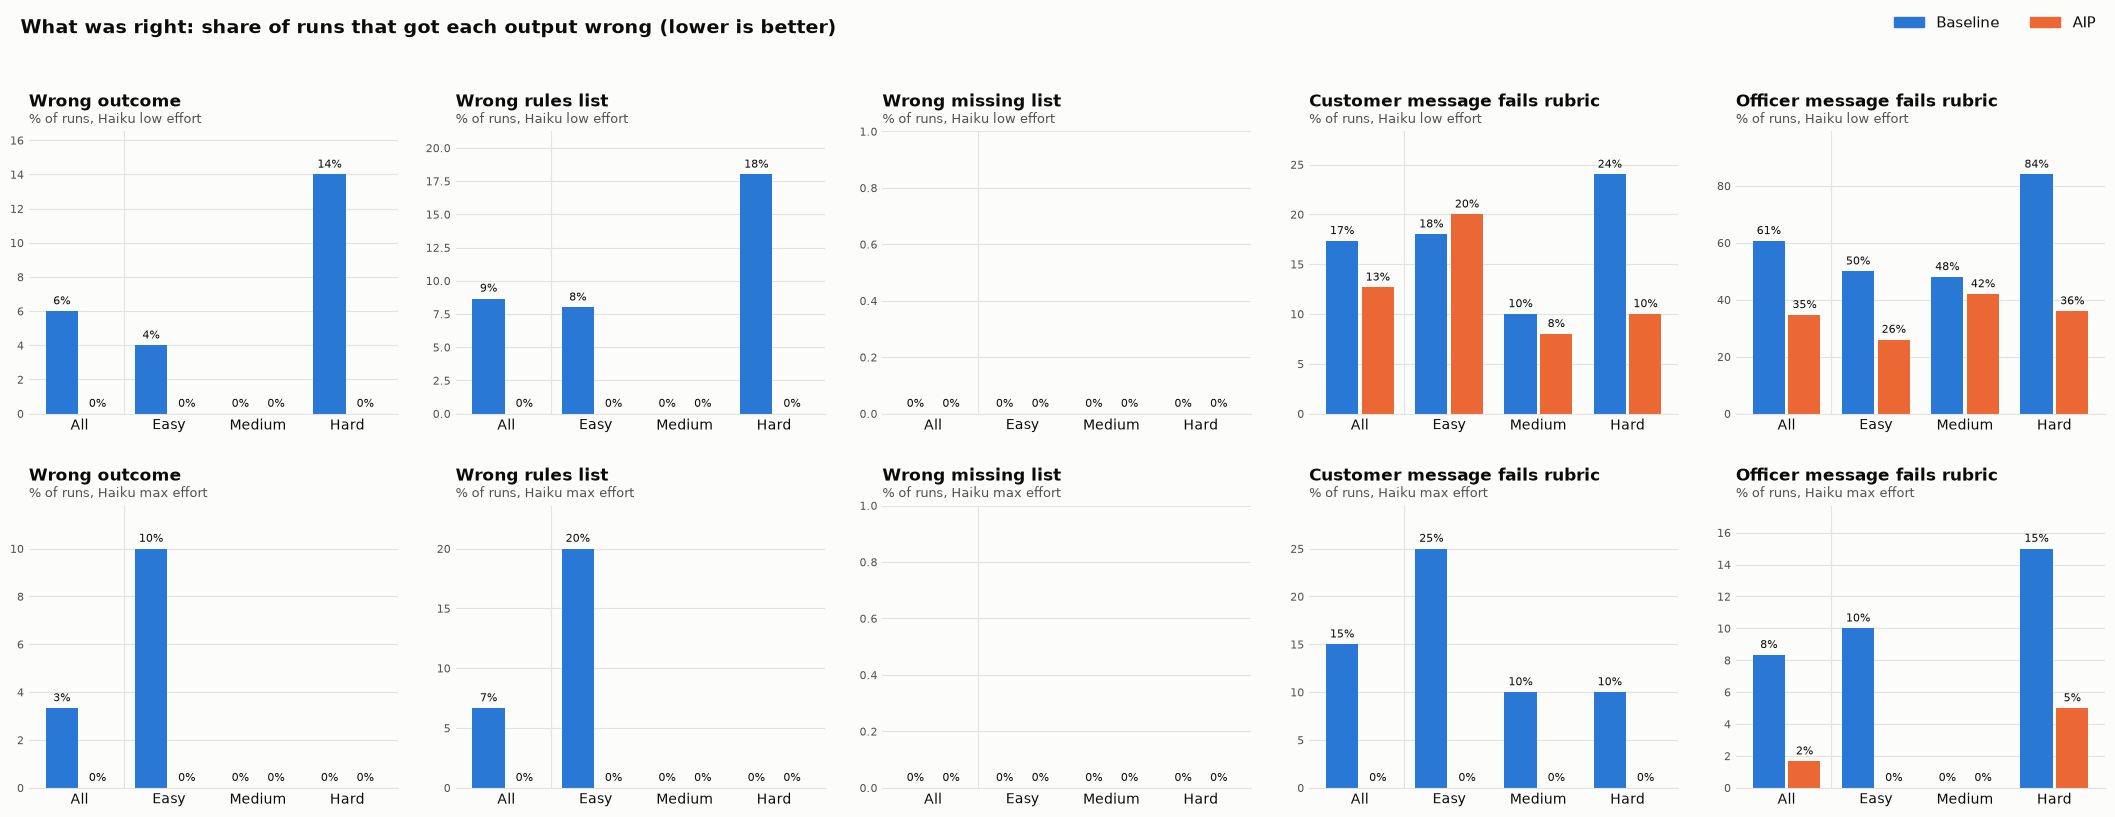

In [17]:
bar_figure(CORRECTNESS, "What was right: share of runs that got each output wrong (lower is better)", "correctness.png")

### A3. Thinking, all tokens, cost and time, by tier

Thinking tokens, all tokens, cost and time for each run.

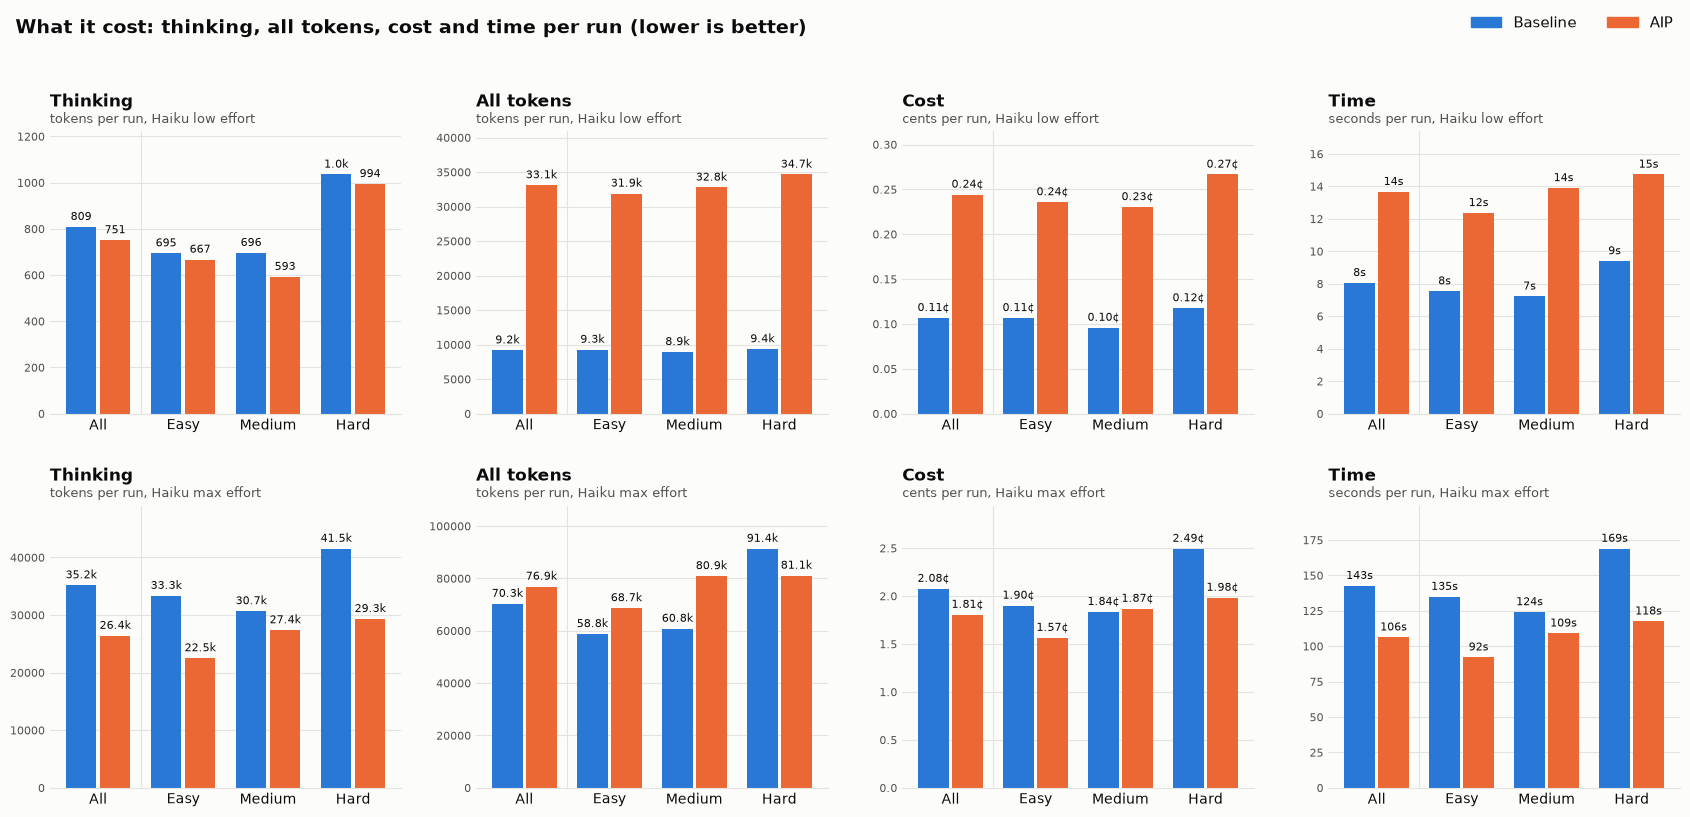

In [18]:
bar_figure(HEADLINE, "What it cost: thinking, all tokens, cost and time per run (lower is better)", "spend.png")

### A4. AIP on Haiku against the baseline on Sonnet, at low effort

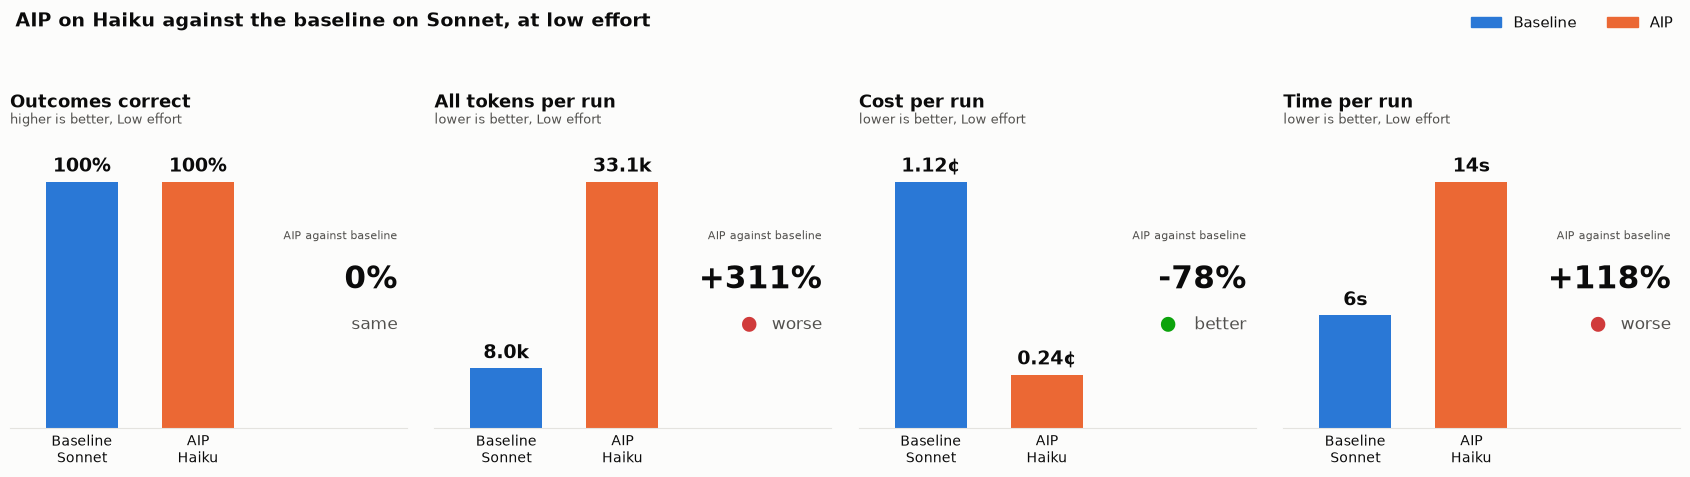

In [19]:
summary_figure([("Low effort", pick("Sonnet low", "Baseline"), pick("Haiku low", "AIP"), "Baseline, Sonnet", "AIP, Haiku")],
               "AIP on Haiku against the baseline on Sonnet, at low effort", "summary-sonnet.png")

### A5. Six measures for every variant

Three settings, each run with and without AIP: Haiku at low effort, Haiku at max effort, and Sonnet at low effort. That is six variants, shown as three pairs in every chart.

- **Top row, what was right:** outcomes correct, and the two lists (failed rules and missing items) both exactly right. 100% is perfect.
- **Thinking**, then **bottom row, what it cost:** all tokens, cost and time for each run.
- **Under each pair:** the change from the baseline to AIP for that model and effort.
- **Scale:** each chart has its own, and the bars in one chart share it, so a small model's bar can be very short beside a large model's. Read the numbers.
- **Runs:** 150 for each low-effort variant (30 applications, 5 runs each), 60 for each max-effort variant (2 runs each).


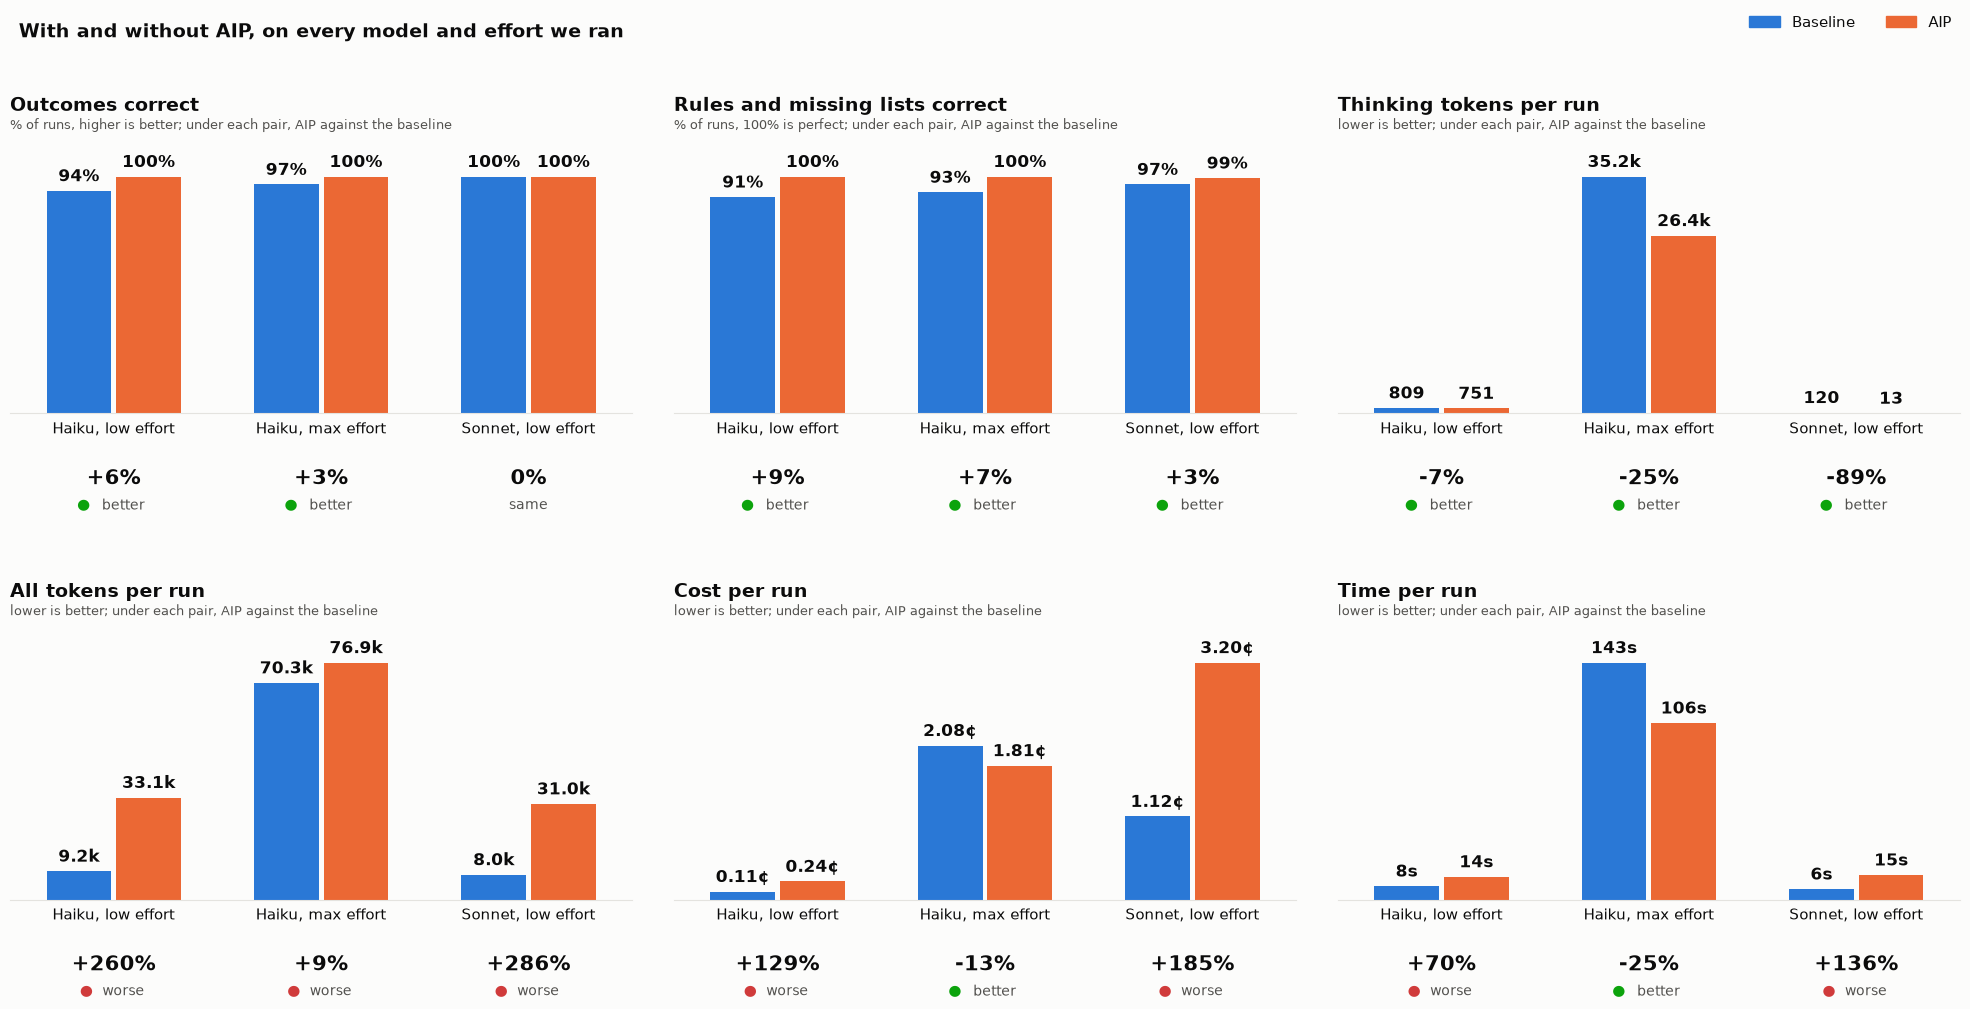

In [20]:
variants_figure(["outcome", "lists", "thinking", "tokens", "cost", "time"],
                "With and without AIP, on every model and effort we ran", "six-summary.png", columns=3)


In [21]:
# Each of the six charts also saved to its own file under bench/results, to arrange as needed.
for key in ("outcome", "lists", "thinking", "tokens", "cost", "time"):
    variants_figure([key], "With and without AIP", f"six-{key}.png", columns=1, show=False)


### A6. AIP on Haiku at low effort against every baseline

AIP on Haiku at low effort, beside the three ways we ran the agent with no procedure: Haiku at low effort, Haiku at max effort, and Sonnet at low effort.

- **Under each baseline:** the change from that baseline to AIP on Haiku at low effort.
- **Precision and recall** are over every rule and missing item the runs named. Precision: of the items named, the share that were right. Recall: of the right items, the share that were named.
- **Area under the precision-recall curve** ranks each item by how often a variant's runs of that application named it, then measures precision and recall as the bar is lowered. 1 is perfect. Haiku at max effort has 2 runs of each application, so its ranking is coarser than the others' 5.
- **Cost** is in dollars for 1,000 runs.


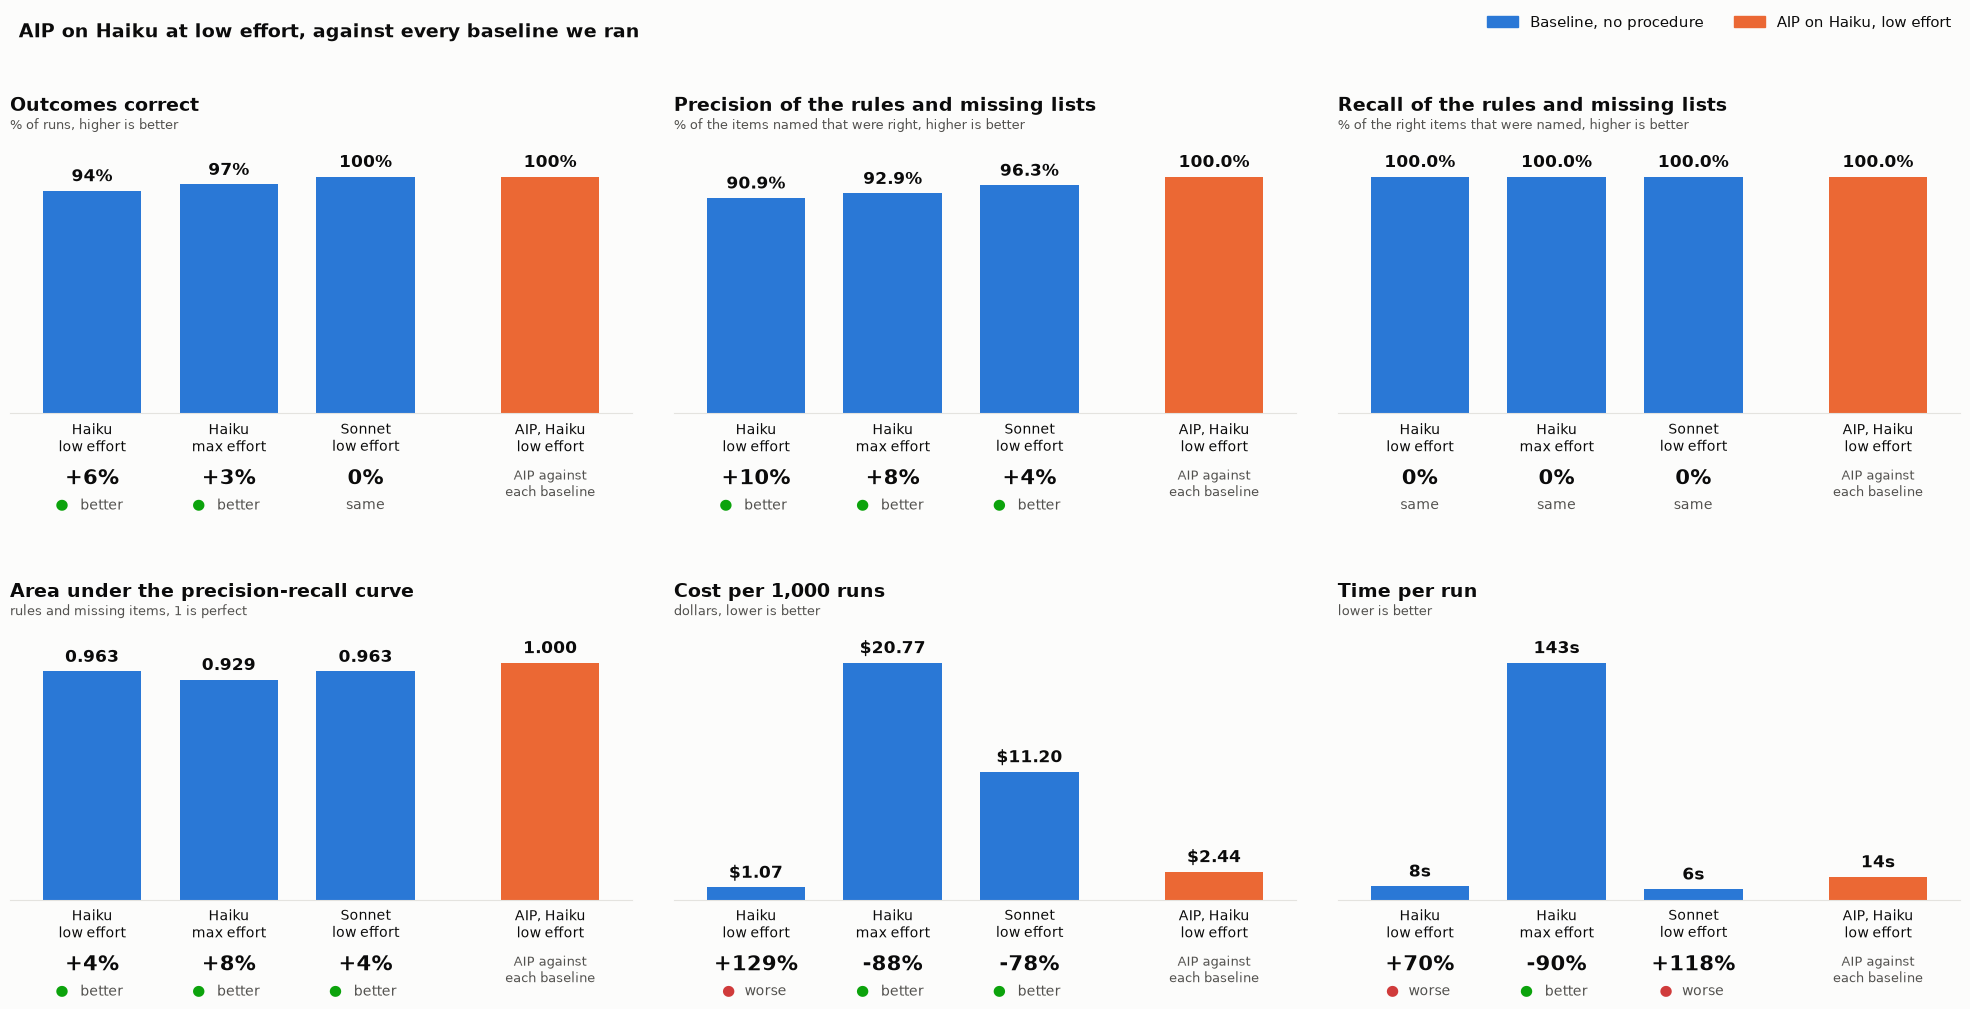

In [22]:
against_figure(["outcome", "precision", "recall", "aucpr", "cost", "time"],
               "AIP on Haiku at low effort, against every baseline we ran", "aip-against-baselines.png")


### A7. Needless reviews: AIP on Haiku at low effort against every baseline

An escalation puts the application in a credit officer's queue. Every wrong outcome in these runs was an application that should have been approved and was escalated instead, so the cost of an error is a review nobody needed.

- **Escalations that did not need a person:** of the runs that escalated, the share where the right outcome was not an escalation.
- **Approvable applications sent to a person:** of the runs on the seven applications that should be approved, the share that were escalated. This one does not depend on how many of the thirty applications are escalations by design.


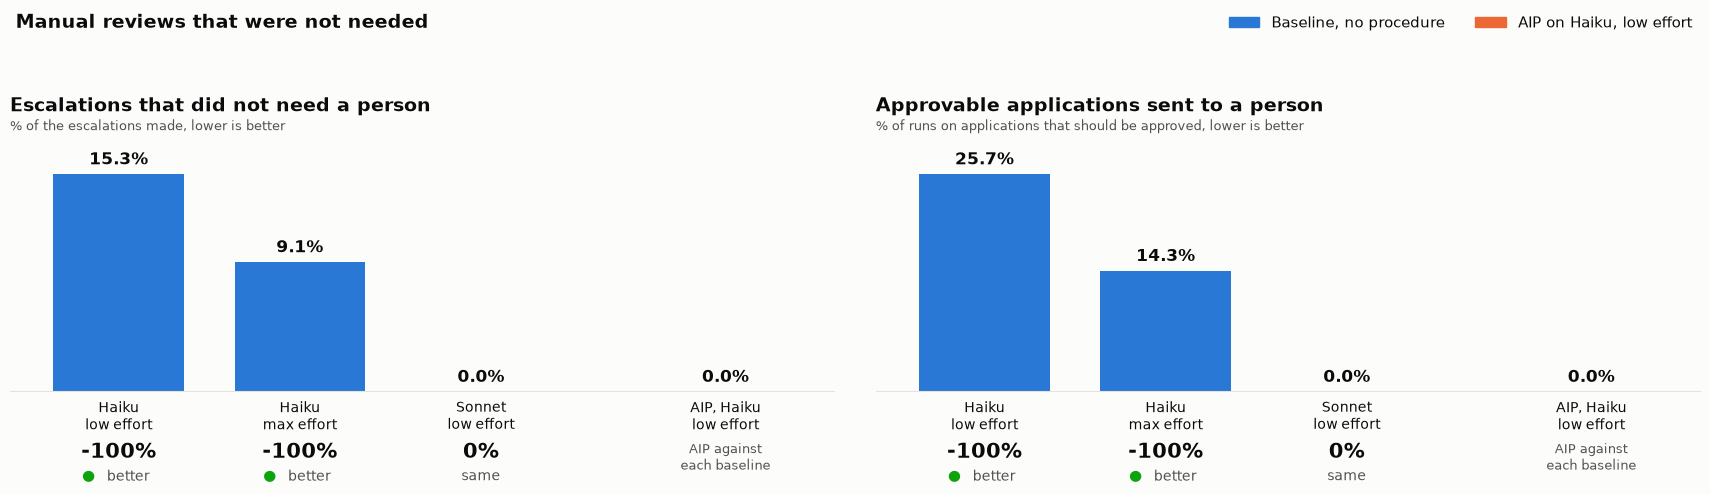

,Escalations made,of which not needed,Runs on approvable applications,of which escalated
"Baseline, Haiku low",59,9,35,9
"Baseline, Haiku max",22,2,14,2
"Baseline, Sonnet low",50,0,35,0
"AIP, Haiku low",50,0,35,0


In [23]:
against_figure(["false_escalations", "needless_reviews"], "Manual reviews that were not needed", "needless-reviews.png", columns=2)
counts = {}
for label, part in [(f"Baseline, {group}", pick(group, "Baseline")) for group in GROUPS] + [("AIP, Haiku low", pick("Haiku low", "AIP"))]:
    sent, clean = part[part.got == "escalate"], part[part.expected == "approve"]
    counts[label] = {"Escalations made": len(sent), "of which not needed": int((sent.expected != "escalate").sum()),
                     "Runs on approvable applications": len(clean), "of which escalated": int((clean.got == "escalate").sum())}
display(pd.DataFrame(counts).T)


### A8. What a missing record could cost

A back-of-hand figure for one exposure: a lookback, where decisions whose record cannot show the checks are reviewed again by hand.

| Assumption | Value | Source |
|---|---|---|
| Decisions in the year under review | 10,000,000 | Assumed: a large consumer lender |
| Share of decisions that need rule checks | 87% | The benchmark's mix: 26 of 30 applications are not returns |
| Time to review one decision again | 10 minutes | Assumed |
| Reviewer, fully loaded | $60 an hour | Assumed |
| Share of records that do not show every check | as measured above | Measured |

This is what one full lookback would cost if it were ordered. It is not a yearly running cost, and the benchmark does not say how likely a lookback is.


In [24]:
DECISIONS, NEED_CHECKS, REVIEW = 10_000_000, 26 / 30, 60 * 10 / 60          # decisions, share needing checks, dollars per review
exposure = {}
for label, part in [(f"Baseline, {group}", pick(group, "Baseline")) for group in GROUPS] + [("AIP, Haiku low", pick("Haiku low", "AIP"))]:
    incomplete = 1 - record_complete(part) / 100
    off = part.groupby("application").apply(lambda mine: len(mine) - collections.Counter(zip(mine.got, mine.said)).most_common(1)[0][1], include_groups=False).sum() / len(part)
    exposure[label] = {"Records missing a check": f"{incomplete:.1%}", "Decisions to review again": f"{DECISIONS * NEED_CHECKS * incomplete:,.0f}",
                       "Cost of one lookback": f"${DECISIONS * NEED_CHECKS * incomplete * REVIEW:,.0f}",
                       "Runs that differ from the usual answer": f"{off:.1%}", "Decisions a year that would not reproduce": f"{DECISIONS * off:,.0f}"}
display(pd.DataFrame(exposure).T)


,Records missing a check,Decisions to review again,Cost of one lookback,Runs that differ from the usual answer,Decisions a year that would not reproduce
"Baseline, Haiku low",7.7%,"666,667","$6,666,667",5.3%,"533,333"
"Baseline, Haiku max",15.4%,"1,333,333","$13,333,333",0.0%,0
"Baseline, Sonnet low",11.5%,"1,000,000","$10,000,000",0.0%,0
"AIP, Haiku low",0.0%,0,$0,0.0%,0


### A9. Every variant, all applications and by tier

In [25]:
def facts(part):
    return {"Runs": ("plain", len(part)), "Outcome correct": ("rate", part.outcome), "Rules list correct": ("rate", part.failed_rules),
            "Missing list correct": ("rate", part.missing),
            "Customer message passes rubric": ("rate", part.customer_message), "Officer message passes rubric": ("rate", part.officer_message),
            "Thinking tokens per run": ("count", part.tokens_thinking.mean()), "All tokens per run": ("count", part.tokens_total.mean()),
            "Cost per run": ("money", part.cost_exact.mean()), "Seconds per run": ("seconds", part.seconds.mean())}

def shown(kind, value):
    if kind == "rate":
        return share(value)
    return {"plain": f"{value}", "count": f"{value:,.0f}", "money": f"${value:.4f}", "seconds": f"{value:.1f}"}[kind]

def table(scope=None):
    out = {}
    for group, arm, _, _ in RUNS:
        f = facts(pick(group, arm, scope))
        out[(group, arm)] = {k: shown(*f[k]) for k in f}
    return pd.DataFrame(out)

display(Markdown("**Every arm, all thirty applications**"))
display(table())
for tier in TIERS:
    display(Markdown(f"**The {tier} tier**"))
    display(table(tier))

**Every arm, all thirty applications**

Haiku low                     Haiku max  \
                                      Baseline             AIP      Baseline   
Runs                                       150             150            60   
Outcome correct                  141/150 (94%)  150/150 (100%)   58/60 (97%)   
Rules list correct               137/150 (91%)  150/150 (100%)   56/60 (93%)   
Missing list correct            150/150 (100%)  150/150 (100%)  60/60 (100%)   
Customer message passes rubric   124/150 (83%)   131/150 (87%)   51/60 (85%)   
Officer message passes rubric     59/150 (39%)    98/150 (65%)   55/60 (92%)   
Thinking tokens per run                    809             751        35,186   
All tokens per run                       9,192          33,107        70,336   
Cost per run                           $0.0011         $0.0024       $0.0208   
Seconds per run                            8.1            13.7         142.6   

                                                  Sonnet low                  
                                         AIP        Baseline             AIP  
Runs                                      60             150             150  
Outcome correct                 60/60 (100%)  150/150 (100%)  150/150 (100%)  
Rules list correct              60/60 (100%)   145/150 (97%)   149/150 (99%)  
Missing list correct            60/60 (100%)  150/150 (100%)  150/150 (100%)  
Customer message passes rubric  60/60 (100%)   136/150 (91%)   136/150 (91%)  
Officer message passes rubric    59/60 (98%)   131/150 (87%)   147/150 (98%)  
Thinking tokens per run               26,413             120              13  
All tokens per run                    76,903           8,048          31,045  
Cost per run                         $0.0181         $0.0112         $0.0320  
Seconds per run                        106.3             6.3            14.7

**The easy tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                  48/50 (96%)  50/50 (100%)   18/20 (90%)   
Rules list correct               46/50 (92%)  50/50 (100%)   16/20 (80%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   41/50 (82%)   40/50 (80%)   15/20 (75%)   
Officer message passes rubric    25/50 (50%)   37/50 (74%)   18/20 (90%)   
Thinking tokens per run                  695           667        33,340   
All tokens per run                     9,277        31,897        58,799   
Cost per run                         $0.0011       $0.0024       $0.0190   
Seconds per run                          7.5          12.4         134.9   

                                                Sonnet low                
                                         AIP      Baseline           AIP  
Runs                                      20            50            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)   45/50 (90%)   49/50 (98%)  
Missing list correct            20/20 (100%)  50/50 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   45/50 (90%)   45/50 (90%)  
Officer message passes rubric   20/20 (100%)   48/50 (96%)   48/50 (96%)  
Thinking tokens per run               22,523            82             3  
All tokens per run                    68,683         7,922        29,921  
Cost per run                         $0.0157       $0.0111       $0.0313  
Seconds per run                         92.2           5.8          12.8

**The medium tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                 50/50 (100%)  50/50 (100%)  20/20 (100%)   
Rules list correct              50/50 (100%)  50/50 (100%)  20/20 (100%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   45/50 (90%)   46/50 (92%)   18/20 (90%)   
Officer message passes rubric    26/50 (52%)   29/50 (58%)  20/20 (100%)   
Thinking tokens per run                  696           593        30,688   
All tokens per run                     8,944        32,772        60,819   
Cost per run                         $0.0010       $0.0023       $0.0184   
Seconds per run                          7.2          13.9         124.1   

                                                Sonnet low                
                                         AIP      Baseline           AIP  
Runs                                      20            50            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)  50/50 (100%)  50/50 (100%)  
Missing list correct            20/20 (100%)  50/50 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   46/50 (92%)   46/50 (92%)  
Officer message passes rubric   20/20 (100%)   48/50 (96%)   49/50 (98%)  
Thinking tokens per run               27,382           114             3  
All tokens per run                    80,927         7,919        30,490  
Cost per run                         $0.0187       $0.0105       $0.0308  
Seconds per run                        109.1           5.9          14.0

**The hard tier**

Haiku low                   Haiku max  \
                                    Baseline           AIP      Baseline   
Runs                                      50            50            20   
Outcome correct                  43/50 (86%)  50/50 (100%)  20/20 (100%)   
Rules list correct               41/50 (82%)  50/50 (100%)  20/20 (100%)   
Missing list correct            50/50 (100%)  50/50 (100%)  20/20 (100%)   
Customer message passes rubric   38/50 (76%)   45/50 (90%)   18/20 (90%)   
Officer message passes rubric     8/50 (16%)   32/50 (64%)   17/20 (85%)   
Thinking tokens per run                1,035           994        41,532   
All tokens per run                     9,354        34,653        91,389   
Cost per run                         $0.0012       $0.0027       $0.0249   
Seconds per run                          9.4          14.7         168.9   

                                                Sonnet low                
                                         AIP      Baseline           AIP  
Runs                                      20            50            50  
Outcome correct                 20/20 (100%)  50/50 (100%)  50/50 (100%)  
Rules list correct              20/20 (100%)  50/50 (100%)  50/50 (100%)  
Missing list correct            20/20 (100%)  50/50 (100%)  50/50 (100%)  
Customer message passes rubric  20/20 (100%)   45/50 (90%)   45/50 (90%)  
Officer message passes rubric    19/20 (95%)   35/50 (70%)  50/50 (100%)  
Thinking tokens per run               29,333           163            34  
All tokens per run                    81,099         8,303        32,724  
Cost per run                         $0.0198       $0.0120       $0.0338  
Seconds per run                        117.6           7.0          17.4